**MScFE 652: Portfolio Management — Group Work Project #2**

*   Hitesh Nanwi
*   Emre Yavuz
*   Kiady Tsilavohery Rasamoelina






---
## What this notebook covers

During this GWP, we 've worked through all seven steps as required for a 3-member group. The work is split as follows:

- **Step 0** – Getting the data ready
- **Step 1** – Finding the optimal Kelly portfolio with a 20% per-asset cap
- **Step 2** – Comparing Kelly, Half-Kelly and Double-Kelly out-of-sample
- **Step 3** – Backtesting using K-Fold cross-validation
- **Step 4** – My individual task: explaining and implementing Denoising, HRP Clustering and Detoning
- **Step 5** – Applying those ML improvements to the actual portfolio
- **Step 6** – Checking whether combining improvements beats using just one
- **Step 7** – A short technical discussion on Estimation Error

We used 10 assets spanning large-cap US equities, a gold ETF, a long-term bond ETF, and two defensive stocks to get a reasonably diversified starting point.

---
## Step 0 – Environment Setup & Data

In [ ]:
# !pip install yfinance scipy scikit-learn matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
import yfinance as yf
from scipy.optimize import minimize
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.figsize': (13, 5), 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 11})
np.random.seed(42)

print('Libraries loaded successfully.')

Libraries loaded successfully.


Assets  : ['AAPL', 'AMZN', 'GLD', 'GOOGL', 'JNJ', 'JPM', 'MSFT', 'PG', 'TLT', 'XOM']
Training: 2024-01-01 to 2025-09-30  ->  437 trading days
Testing : 2025-10-01  to 2025-12-31   ->  63 trading days
Full    : 2024-01-03 to 2025-12-30  ->  500 days total


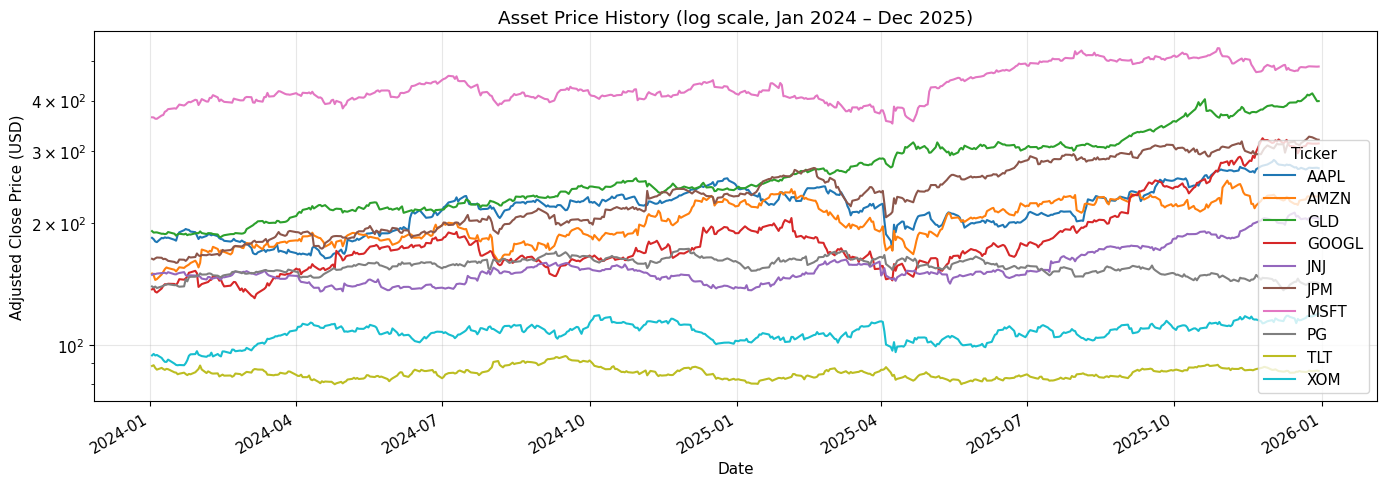

In [ ]:
# We chose 10 assets to keep the portfolio manageable but diverse enough:
# 4 large-cap tech stocks, 1 bank, 1 energy company, 2 defensives (JNJ, PG), gold (GLD) and bonds (TLT)
TICKERS = ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM', 'XOM', 'JNJ', 'PG', 'GLD', 'TLT']

# Pull daily adjusted close prices over the full 2-year window
raw = yf.download(TICKERS, start='2024-01-01', end='2025-12-31', auto_adjust=True, progress=False)['Close']
raw.ffill(inplace=True)   # fill any missing trading days
raw.dropna(inplace=True)

# We using log returns here because they're additive over time and more numerically stable
# for the Kelly criterion than simple percentage returns
returns = np.log(raw / raw.shift(1)).dropna()

# Split the data per the assignment instructions
TRAIN_START, TRAIN_END = '2024-01-01', '2025-09-30'   # training (in-sample)
TEST_START,  TEST_END  = '2025-10-01', '2025-12-31'   # testing  (out-of-sample)

train_ret = returns[TRAIN_START:TRAIN_END]
test_ret  = returns[TEST_START:TEST_END]
full_ret  = returns   # used later for K-Fold backtesting

print(f'Assets  : {list(returns.columns)}')
print(f'Training: {TRAIN_START} to {TRAIN_END}  ->  {len(train_ret)} trading days')
print(f'Testing : {TEST_START}  to {TEST_END}   ->  {len(test_ret)} trading days')
print(f'Full    : {full_ret.index[0].date()} to {full_ret.index[-1].date()}  ->  {len(full_ret)} days total')

# Quick look at how prices moved over the study window
raw.plot(logy=True, title='Asset Price History (log scale, Jan 2024 – Dec 2025)', figsize=(14, 5))
plt.xlabel('Date'); plt.ylabel('Adjusted Close Price (USD)')
plt.tight_layout(); plt.show()

---
## Step 1 – Finding the Optimal Kelly Portfolio

### The idea behind Kelly

The Kelly Criterion was originally developed for gambling but maps cleanly onto portfolio allocation. The goal is to maximise the **expected growth rate of wealth** over time, which is equivalent to maximising the expected log return of the portfolio each period.

Mathematically, we want to find weights $w$ that solve:
$$w^* = \arg\max_{w}\; \mu^\top w - \tfrac{1}{2}\, w^\top \Sigma\, w$$

where $\mu$ is the vector of annualised expected returns and $\Sigma$ is the annualised covariance matrix.

We also have two constraints:
- Weights must sum to 1 (fully invested portfolio)
- No single asset can exceed 20% of the portfolio (concentration cap)

The 20% cap is a practical risk management rule — without it, the unconstrained Kelly portfolio can become very concentrated and aggressive.

In [ ]:
# We 'll define all the performance and optimisation helper functions here
# so they can be reused cleanly across all steps below

def annualise(ret_series):
    # Multiply daily mean by 252 trading days to annualise
    return ret_series.mean() * 252

def annualise_cov(ret_df):
    return ret_df.cov() * 252

def kelly_opt(ret, cov_mat=None, cap=0.20):
    # Optimise Kelly weights subject to a per-asset concentration cap
    # If a pre-built covariance matrix is passed in, we use that (useful for denoised/detoned versions)
    mu = annualise(ret).values
    S  = annualise_cov(ret).values if cov_mat is None else cov_mat
    n  = len(mu)
    x0 = np.ones(n) / n   # start from equal weight
    result = minimize(
        fun         = lambda w: -(w @ mu - 0.5 * w @ S @ w),   # negative because we minimise
        x0          = x0,
        method      = 'SLSQP',
        bounds      = [(0, cap)] * n,
        constraints = [{'type': 'eq', 'fun': lambda w: w.sum() - 1}],
        options     = {'ftol': 1e-12, 'maxiter': 3000}
    )
    return pd.Series(result.x, index=ret.columns)

def port_ret_series(w, ret_df):
    return ret_df @ w

def cum_return(r):
    # Works correctly with log returns
    return (np.exp(r.sum()) - 1) * 100

def sharpe(r, rf=0.0):
    excess = r - rf / 252
    return np.sqrt(252) * excess.mean() / excess.std() if excess.std() > 0 else np.nan

def max_drawdown(r):
    equity = np.exp(r.cumsum())
    return ((equity - equity.cummax()) / equity.cummax()).min() * 100

def cvar_95(r):
    # Average loss in the worst 5% of days — also called Expected Shortfall
    var_5 = np.percentile(r, 5)
    return r[r <= var_5].mean() * 100

def sortino(r, rf=0.0):
    excess   = r - rf / 252
    downside = excess[excess < 0].std()
    return np.sqrt(252) * excess.mean() / downside if downside > 0 else np.nan

def score_table(strats_dict, ret_df):
    # Builds a clean performance comparison table across multiple strategies
    rows = {}
    for name, w in strats_dict.items():
        r = port_ret_series(w, ret_df)
        rows[name] = {
            'Cum Return (%)'  : round(cum_return(r), 2),
            'Sharpe Ratio'    : round(sharpe(r), 4),
            'Sortino Ratio'   : round(sortino(r), 4),
            'Max Drawdown (%)': round(max_drawdown(r), 2),
            '95% CVaR (%)'    : round(cvar_95(r), 4)
        }
    return pd.DataFrame(rows).T

print('Helper functions ready.')

Helper functions ready.


Optimal Kelly Weights (20% cap):
Ticker
AMZN     0.2
GLD      0.2
JPM      0.2
GOOGL    0.2
MSFT     0.2
XOM      0.0
JNJ      0.0
AAPL     0.0
PG       0.0
TLT      0.0

Weights sum to: 1.000000
Largest single position: 0.2000  (cap is 0.20, so constraint is binding if this = 0.20)


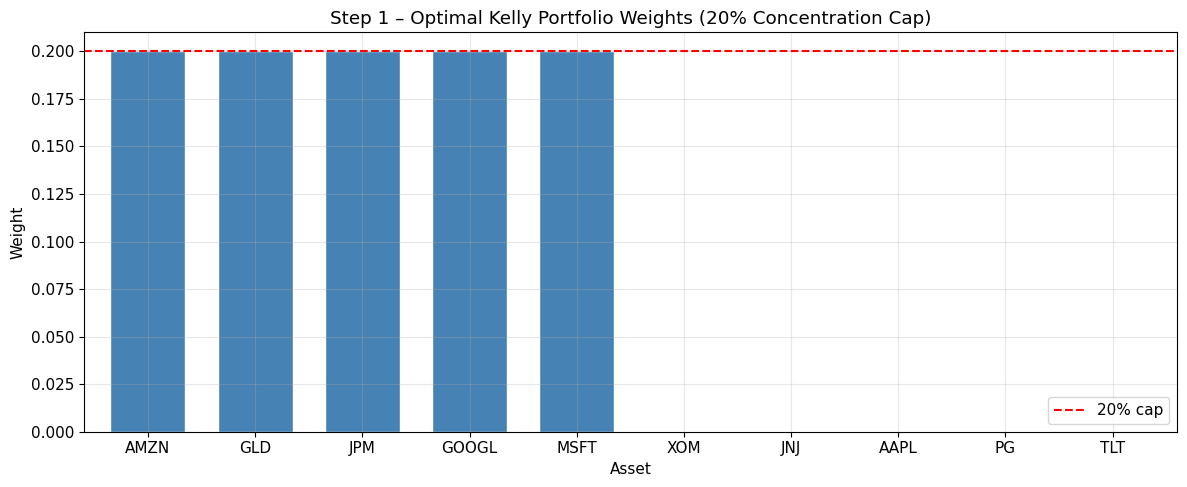

In [ ]:
# Run the Kelly optimisation on the training data
kelly_w = kelly_opt(train_ret, cap=0.20)

print('Optimal Kelly Weights (20% cap):')
print(kelly_w.sort_values(ascending=False).round(4).to_string())
print(f'\nWeights sum to: {kelly_w.sum():.6f}')
print(f'Largest single position: {kelly_w.max():.4f}  (cap is 0.20, so constraint is binding if this = 0.20)')

# Visualise how the 20% cap distributes across assets
fig, ax = plt.subplots(figsize=(12, 5))
kelly_w.sort_values(ascending=False).plot(kind='bar', ax=ax, color='steelblue', edgecolor='white', width=0.7)
ax.axhline(0.20, linestyle='--', color='red', linewidth=1.5, label='20% cap')
ax.set_title('Step 1 – Optimal Kelly Portfolio Weights (20% Concentration Cap)')
ax.set_ylabel('Weight'); ax.set_xlabel('Asset')
ax.legend(); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

---
## Step 2 – Kelly vs Half-Kelly vs Double-Kelly: Out-of-Sample

One of the well-known issues with the full Kelly strategy is that it can be quite volatile — the portfolio swings a lot even if the long-run growth rate is optimal. In practice, many traders use a **fractional Kelly** to tone down the risk.

Here I compare three variants on the **out-of-sample period (Oct – Dec 2025)**:
- **Kelly** – the weights computed in Step 1
- **Half-Kelly** – simply multiply each weight by 0.5 (less aggressive, lower variance)
- **Double-Kelly** – multiply by 2, clip at 1.0 and renormalise (more aggressive, higher risk)

The model is trained on Jan 2024 – Sep 2025 data, then applied as-is to the Oct – Dec 2025 period without refitting.

Out-of-Sample Performance (Oct – Dec 2025)
              Cum Return (%)  Sharpe Ratio  Sortino Ratio  Max Drawdown (%)  95% CVaR (%)
Kelly                   8.32        2.1055         3.3495             -5.31       -1.8312
Half-Kelly              4.08        2.1055         3.3495             -2.69       -0.9156
Double-Kelly            8.32        2.1055         3.3495             -5.31       -1.8312


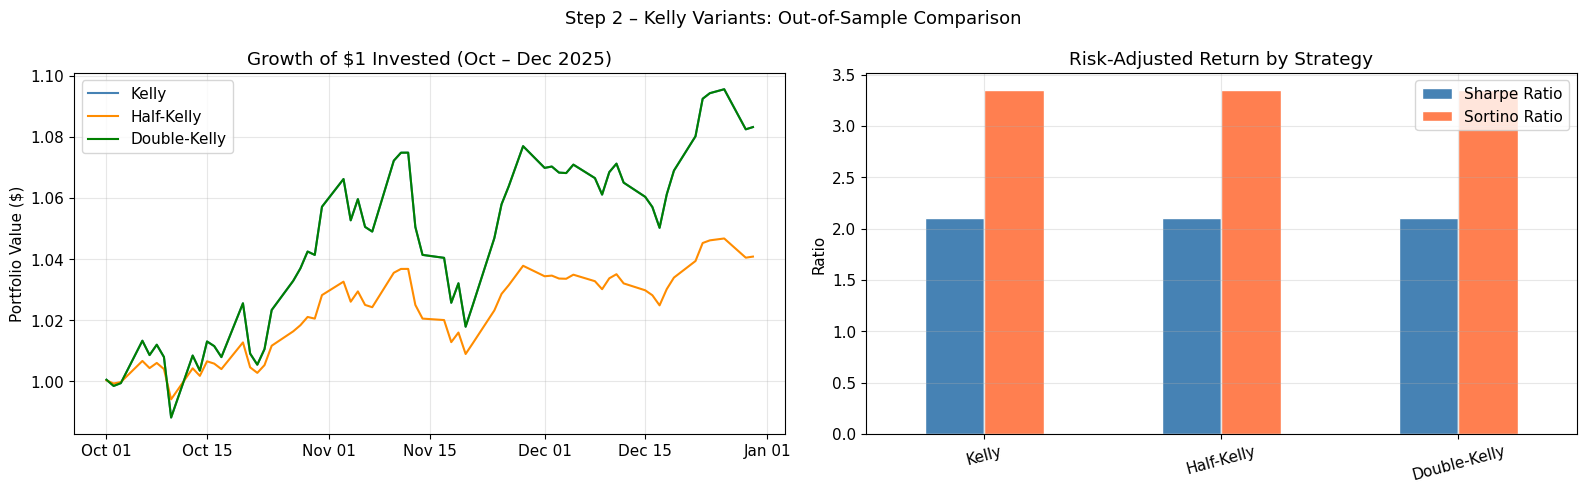

In [ ]:
# Half-Kelly: scale all weights down by half
w_half = kelly_w * 0.5

# Double-Kelly: scale up, clip anything above 100% to avoid infeasibility, then renormalise
w_double = np.clip(kelly_w * 2, 0, 1)
w_double = pd.Series(w_double.values / w_double.sum(), index=kelly_w.index)

kelly_strats = {
    'Kelly'       : kelly_w,
    'Half-Kelly'  : w_half,
    'Double-Kelly': w_double
}

# Compute performance metrics on the test set
perf_table = score_table(kelly_strats, test_ret)
print('Out-of-Sample Performance (Oct – Dec 2025)')
print('=' * 60)
print(perf_table.to_string())

# Plot equity curves and risk-adjusted ratios side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

colors = ['steelblue', 'darkorange', 'green']
for (name, w), c in zip(kelly_strats.items(), colors):
    equity = np.exp(port_ret_series(w, test_ret).cumsum())
    axes[0].plot(equity.index, equity.values, label=name, color=c)
axes[0].set_title('Growth of $1 Invested (Oct – Dec 2025)')
axes[0].set_ylabel('Portfolio Value ($)'); axes[0].legend()
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

perf_table[['Sharpe Ratio', 'Sortino Ratio']].plot(kind='bar', ax=axes[1], color=['steelblue', 'coral'], edgecolor='white')
axes[1].set_title('Risk-Adjusted Return by Strategy')
axes[1].set_ylabel('Ratio'); axes[1].tick_params(axis='x', rotation=15)

plt.suptitle('Step 2 – Kelly Variants: Out-of-Sample Comparison', fontsize=13)
plt.tight_layout(); plt.show()

---
## Step 3 – Backtesting with K-Fold Cross-Validation

### Why not just use a train/test split?

A single train/test split only tells us how the model performed in one specific out-of-sample window. That can be lucky or unlucky depending on what happened in that period. K-Fold CV gives us a much more robust view by testing across **multiple non-overlapping out-of-sample windows**.

### Why TimeSeriesSplit instead of standard K-Fold?

Standard K-Fold randomly shuffles observations before splitting. For time series, this creates **look-ahead bias** — we'd be training on future data to predict the past, which is not realistic. `TimeSeriesSplit` always keeps the training window strictly before the test window, growing the training set cumulatively:

- Fold 1: Train on days [1 : T1], test on [T1 : T2]
- Fold 2: Train on days [1 : T2], test on [T2 : T3]
- ... and so on for K=5 folds

For each fold, I refit the Kelly weights on the training sub-period and evaluate on the held-out sub-period. The full 2024–2025 dataset is used here.

K-Fold (K=5) Backtesting Results:
      Train Days  Test Days  Cum Return (%)  Sharpe Ratio  Max Drawdown (%)  95% CVaR (%)
Fold                                                                                     
1             85         83            2.29        0.5548             -8.13       -1.9401
2            168         83            9.27        2.3396             -2.94       -1.6909
3            251         83           -4.16       -0.4562            -20.72       -4.0463
4            334         83           18.35        4.4080             -2.41       -1.4872
5            417         83           14.54        2.8254             -5.31       -1.7428

Average across all folds:
Cum Return (%)      8.0580
Sharpe Ratio        1.9343
Max Drawdown (%)   -7.9020
95% CVaR (%)       -2.1815


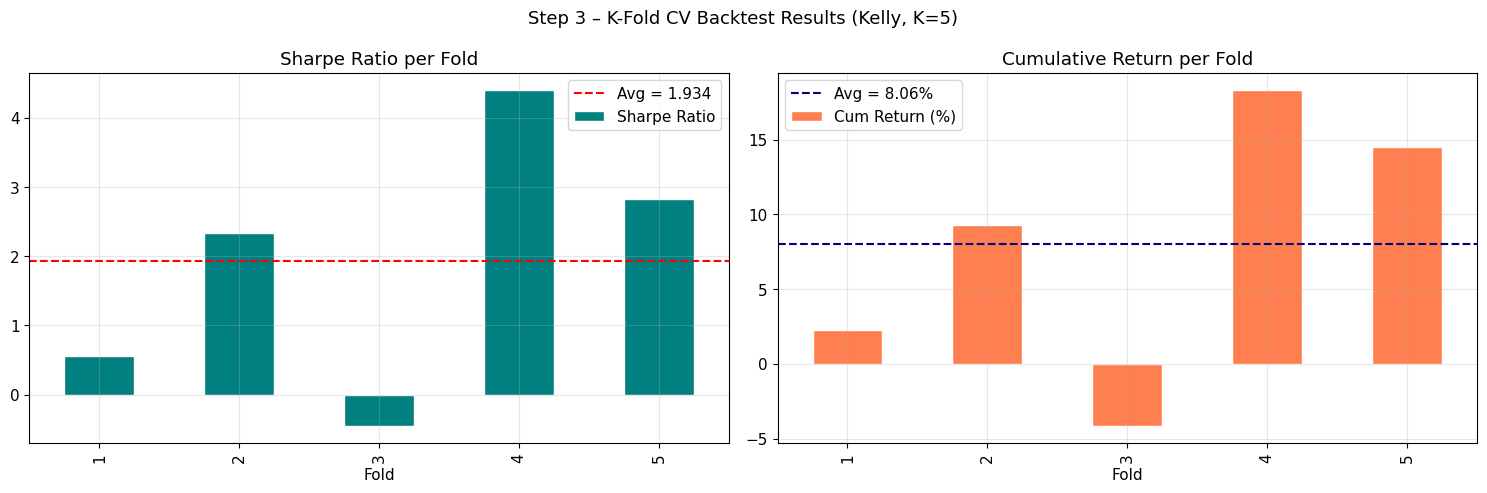

In [ ]:
K    = 5
tscv = TimeSeriesSplit(n_splits=K)
fold_results = []

for fold, (tr_idx, te_idx) in enumerate(tscv.split(full_ret.values), start=1):
    # Refit Kelly on just this fold's training data
    w_fold = kelly_opt(full_ret.iloc[tr_idx], cap=0.20)
    r_fold = port_ret_series(w_fold, full_ret.iloc[te_idx])

    fold_results.append({
        'Fold'            : fold,
        'Train Days'      : len(tr_idx),
        'Test Days'       : len(te_idx),
        'Cum Return (%)'  : round(cum_return(r_fold), 2),
        'Sharpe Ratio'    : round(sharpe(r_fold), 4),
        'Max Drawdown (%)': round(max_drawdown(r_fold), 2),
        '95% CVaR (%)'    : round(cvar_95(r_fold), 4)
    })

cv_df    = pd.DataFrame(fold_results).set_index('Fold')
mean_row = cv_df[['Cum Return (%)','Sharpe Ratio','Max Drawdown (%)','95% CVaR (%)']].mean()

print('K-Fold (K=5) Backtesting Results:')
print('=' * 60)
print(cv_df.to_string())
print('\nAverage across all folds:')
print(mean_row.round(4).to_string())

# Visualise the consistency of performance across folds
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cv_df['Sharpe Ratio'].plot(kind='bar', ax=axes[0], color='teal', edgecolor='white')
axes[0].axhline(mean_row['Sharpe Ratio'], linestyle='--', color='red', label=f"Avg = {mean_row['Sharpe Ratio']:.3f}")
axes[0].set_title('Sharpe Ratio per Fold'); axes[0].set_xlabel('Fold'); axes[0].legend()

cv_df['Cum Return (%)'].plot(kind='bar', ax=axes[1], color='coral', edgecolor='white')
axes[1].axhline(mean_row['Cum Return (%)'], linestyle='--', color='navy', label=f"Avg = {mean_row['Cum Return (%)']:.2f}%")
axes[1].set_title('Cumulative Return per Fold'); axes[1].set_xlabel('Fold'); axes[1].legend()

plt.suptitle('Step 3 – K-Fold CV Backtest Results (Kelly, K=5)', fontsize=13)
plt.tight_layout(); plt.show()

---
## Step 4 – ML Improvements: Denoising, Clustering (HRP) and Detoning

One of the core issues with classical portfolio optimisation — whether MVO or Kelly — is that both rely on a **sample covariance matrix** that is estimated from a finite amount of data. With 10 assets and around 460 trading days, the ratio $q = N/T \approx 0.02$, which sounds small, but the covariance matrix still ends up carrying a surprising amount of noise. This noise gets amplified when we compute $\Sigma^{-1}$, leading to extreme and unstable weights.

The three ML-inspired techniques below each address a different aspect of this problem.

---
### 4a. Denoising via Random Matrix Theory (Marchenko-Pastur)

The insight here comes from physics. If you took $T$ observations of $N$ completely random (uncorrelated) variables and computed their sample correlation matrix, you'd still see non-zero off-diagonal entries — just due to chance. The **Marchenko-Pastur distribution** tells us exactly what the eigenvalue spectrum of such a pure-noise matrix looks like.

Specifically, all eigenvalues of a pure-noise correlation matrix fall within the range $[\lambda^-, \lambda^+]$ where:
$$\lambda^{\pm} = \left(1 \pm \sqrt{\frac{N}{T}}\right)^2$$

Any eigenvalue of our actual correlation matrix that sits **below** $\lambda^+$ is therefore indistinguishable from noise. We clean the matrix by replacing all noise eigenvalues with their mean, then reconstructing $\Sigma$.

**Why does this help?** A denoised $\Sigma$ is better conditioned — its condition number drops — which makes $\Sigma^{-1}$ more numerically stable and less likely to produce extreme portfolio weights.

---
### 4b. Clustering – Hierarchical Risk Parity (HRP)

HRP takes a completely different approach to the inversion problem: instead of inverting $\Sigma$, it bypasses it entirely. The algorithm (introduced by Marcos López de Prado in 2016) works in three stages:

1. **Tree clustering** – build a dendrogram of assets based on correlation distances, where $d_{ij} = \sqrt{(1-\rho_{ij})/2}$. Assets that move together get clustered together.

2. **Quasi-diagonalisation** – reorder the covariance matrix so that similar assets are adjacent. This reveals the block structure in the data.

3. **Recursive bisection** – starting from the full portfolio, recursively split it into two halves. At each split, allocate more weight to the lower-risk half, proportional to inverse cluster variance:
$$\alpha = \frac{\tilde{V}_R}{\tilde{V}_L + \tilde{V}_R}$$

This naturally spreads risk across clusters (think: sectors), not just individual assets, and doesn't require $\Sigma^{-1}$ at any point.

---
### 4c. Detoning

Even after denoising, the correlation matrix still contains a strong **market factor** — a single dominant eigenvector that explains a large chunk of overall variance. This market component pushes up all pairwise correlations and makes it hard to see genuine sector-level or company-specific relationships.

Detoning removes this market eigenvector before clustering:
$$\tilde{C} = C - \sum_{i=1}^{k} \lambda_i\, v_i v_i^\top$$

After removal, the matrix is rescaled so the diagonal stays at 1. The result is a correlation structure that reflects *genuine co-movement* between assets, making the HRP dendrogram much more informative.

A useful analogy: if you're trying to cluster students by their individual interests, you'd first want to remove the fact that they all have "being students" in common — that's the market factor. Detoning does exactly this for asset correlations.

In [ ]:
def cov2corr(cov):
    # Standard conversion: normalise rows and columns by their standard deviations
    s = np.sqrt(np.diag(cov))
    return np.clip(cov / np.outer(s, s), -1, 1)


def denoise_cov(cov, T, N):
    # Marchenko-Pastur denoising
    # q = N/T tells us how much noise to expect in the eigenvalue spectrum
    q           = N / T
    lambda_plus = (1 + np.sqrt(q)) ** 2   # upper edge of the MP distribution

    corr = cov2corr(cov)
    eigenvals, eigenvecs = np.linalg.eigh(corr)

    # Eigenvalues below lambda_plus are noise – replace them with their mean
    noise_mask       = eigenvals <= lambda_plus
    noise_mean       = eigenvals[noise_mask].mean() if noise_mask.any() else 0
    eigenvals_clean  = eigenvals.copy()
    eigenvals_clean[noise_mask] = noise_mean

    # Rebuild the cleaned correlation matrix and enforce unit diagonal
    corr_clean = eigenvecs @ np.diag(eigenvals_clean) @ eigenvecs.T
    np.fill_diagonal(corr_clean, 1.0)

    # Convert back to covariance space
    s = np.sqrt(np.diag(cov))
    return corr_clean * np.outer(s, s), lambda_plus, noise_mask.sum()


def detone_cov(cov, k=1):
    # Remove the top-k (market) eigenvectors to expose idiosyncratic correlations
    s = np.sqrt(np.diag(cov))
    corr = cov2corr(cov)
    eigenvals, eigenvecs = np.linalg.eigh(corr)

    for i in range(1, k + 1):
        v    = eigenvecs[:, -i].reshape(-1, 1)
        corr -= eigenvals[-i] * (v @ v.T)   # subtract the market component

    # Rescale so the diagonal is 1 again
    d    = np.sqrt(np.abs(np.diag(corr)))
    d[d == 0] = 1
    corr = corr / np.outer(d, d)
    np.fill_diagonal(corr, 1.0)
    return corr * np.outer(s, s)


def hrp_weights(ret, cov_mat=None):
    # HRP: build a dendrogram, then allocate risk via recursive bisection
    cov   = annualise_cov(ret).values if cov_mat is None else cov_mat
    corr  = cov2corr(cov)

    # Correlation-based distance matrix
    dist  = np.sqrt(np.clip((1 - corr) / 2, 0, 1))
    link  = linkage(squareform(dist, checks=False), method='single')
    order = [int(x) for x in dendrogram(link, no_plot=True)['ivl']]

    # Recursive bisection: split portfolio in half, weight by inverse cluster variance
    w     = pd.Series(1.0, index=order)
    items = [order]
    while items:
        next_items = []
        for cluster in items:
            if len(cluster) <= 1:
                continue
            mid = len(cluster) // 2
            L, R = cluster[:mid], cluster[mid:]
            cL = cov[np.ix_(L, L)]; wL = 1 / np.diag(cL); wL /= wL.sum()
            cR = cov[np.ix_(R, R)]; wR = 1 / np.diag(cR); wR /= wR.sum()
            vL    = wL @ cL @ wL
            vR    = wR @ cR @ wR
            alpha = vR / (vL + vR)   # proportion going to left cluster
            w[L] *= alpha
            w[R] *= (1 - alpha)
            next_items += [L, R]
        items = next_items

    w_out = pd.Series({ret.columns[i]: w.get(i, 1.0 / len(order)) for i in range(len(ret.columns))})
    return w_out / w_out.sum()

print('Denoising, detoning and HRP functions are ready.')

Denoising, detoning and HRP functions are ready.


Training period: T = 437 days, N = 10 assets
q = N/T = 0.0229  →  MP upper bound lambda+ = 1.3254
Number of noise eigenvalues replaced: 8 out of 10

HRP Weights (Raw covariance):
AAPL     0.0287
AMZN     0.0413
GLD      0.1639
GOOGL    0.0262
JNJ      0.1147
JPM      0.0584
MSFT     0.0792
PG       0.1249
TLT      0.2720
XOM      0.0906

HRP Weights (Denoised + Detoned):
AAPL     0.0372
AMZN     0.0720
GLD      0.2619
GOOGL    0.0767
JNJ      0.0528
JPM      0.1177
MSFT     0.1395
PG       0.0575
TLT      0.1203
XOM      0.0643


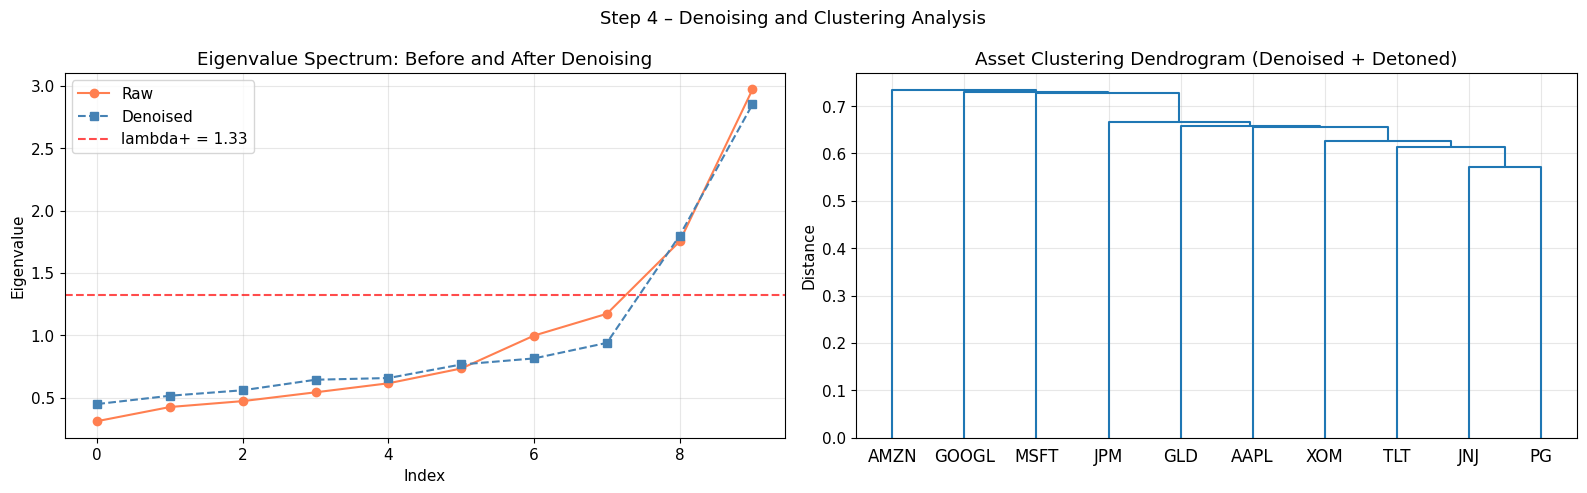

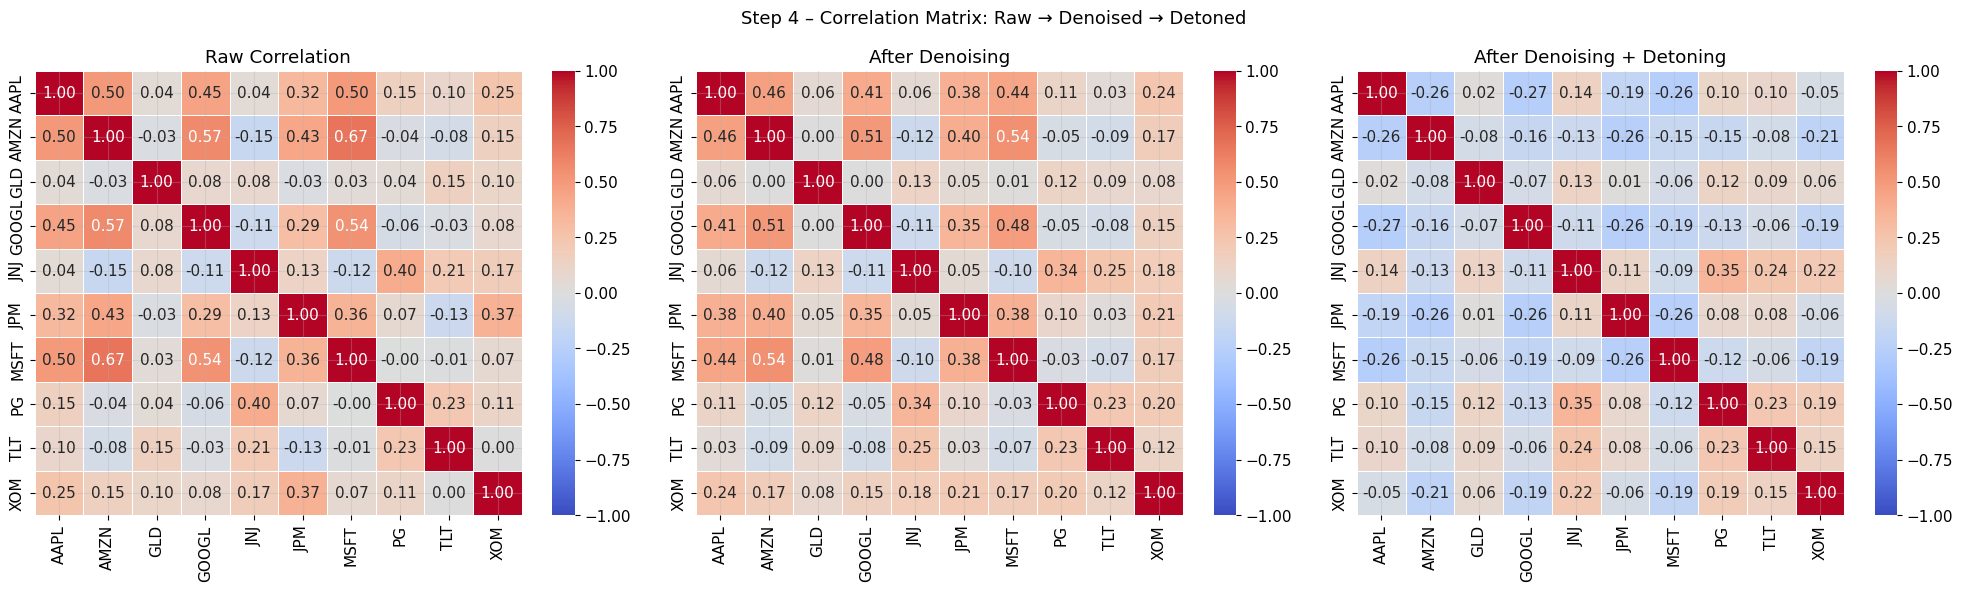

In [ ]:
# Build raw, denoised and denoised+detoned covariance matrices from training data
T_train, N = train_ret.shape
cov_raw    = annualise_cov(train_ret).values

cov_den, lam_plus, n_noise = denoise_cov(cov_raw, T_train, N)
cov_det    = detone_cov(cov_den, k=1)   # apply detoning on top of denoised matrix

# HRP weights under each version of the covariance matrix
hrp_raw_w = hrp_weights(train_ret, cov_mat=cov_raw)
hrp_den_w = hrp_weights(train_ret, cov_mat=cov_den)
hrp_det_w = hrp_weights(train_ret, cov_mat=cov_det)

print(f'Training period: T = {T_train} days, N = {N} assets')
print(f'q = N/T = {N/T_train:.4f}  →  MP upper bound lambda+ = {lam_plus:.4f}')
print(f'Number of noise eigenvalues replaced: {n_noise} out of {N}')
print()
print('HRP Weights (Raw covariance):')
print(hrp_raw_w.round(4).to_string())
print('\nHRP Weights (Denoised + Detoned):')
print(hrp_det_w.round(4).to_string())

# Plot 1: Eigenvalue spectrum before and after denoising
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ev_raw = sorted(np.linalg.eigh(cov2corr(cov_raw))[0])
ev_den = sorted(np.linalg.eigh(cov2corr(cov_den))[0])
axes[0].plot(ev_raw, 'o-', label='Raw', color='coral')
axes[0].plot(ev_den, 's--', label='Denoised', color='steelblue')
axes[0].axhline(lam_plus, linestyle='--', color='red', alpha=0.7, label=f'lambda+ = {lam_plus:.2f}')
axes[0].set_title('Eigenvalue Spectrum: Before and After Denoising')
axes[0].set_xlabel('Index'); axes[0].set_ylabel('Eigenvalue'); axes[0].legend()

# Plot 2: HRP dendrogram on the clean (detoned) correlation matrix
corr_det = cov2corr(cov_det)
dist_det = np.sqrt(np.clip((1 - corr_det) / 2, 0, 1))
link_det = linkage(squareform(dist_det, checks=False), method='single')
dendrogram(link_det, labels=list(train_ret.columns), ax=axes[1], color_threshold=0.4)
axes[1].set_title('Asset Clustering Dendrogram (Denoised + Detoned)')
axes[1].set_ylabel('Distance')

plt.suptitle('Step 4 – Denoising and Clustering Analysis', fontsize=13)
plt.tight_layout(); plt.show()

# Plot 3: Heatmaps showing how the correlation structure evolves through each step
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
labels = list(train_ret.columns)
kw     = dict(annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, linewidths=0.5)

sns.heatmap(cov2corr(cov_raw), xticklabels=labels, yticklabels=labels, ax=axes[0], **kw)
axes[0].set_title('Raw Correlation')
sns.heatmap(cov2corr(cov_den), xticklabels=labels, yticklabels=labels, ax=axes[1], **kw)
axes[1].set_title('After Denoising')
sns.heatmap(cov2corr(cov_det), xticklabels=labels, yticklabels=labels, ax=axes[2], **kw)
axes[2].set_title('After Denoising + Detoning')

plt.suptitle('Step 4 – Correlation Matrix: Raw → Denoised → Detoned', fontsize=13)
plt.tight_layout(); plt.show()

---
## Step 5 – Applying the ML Improvements to the Portfolio

Now I'll put together five strategies that combine the techniques from Step 4 in different ways. The baseline is the raw Kelly portfolio from Step 1. From there, I layer in denoising, HRP, and detoning:

| Strategy | What it uses |
|----------|-------------|
| Kelly (Baseline) | Raw covariance, Kelly weights |
| Kelly + Denoise | Denoised covariance, Kelly weights |
| HRP (Raw) | Raw covariance, HRP allocation |
| HRP + Denoise | Denoised covariance, HRP allocation |
| HRP + Denoise + Detone | Denoised then detoned covariance, HRP allocation |

My recommended pipeline is **Denoise → Detone → HRP** in that order, because:
- Denoising first stabilises the covariance estimate
- Detoning then strips the market factor before clustering, so HRP groups assets by genuine co-movement
- HRP finally allocates without needing to invert the covariance matrix

Portfolio Weights by Strategy:
        1. Kelly (Baseline)  2. Kelly + Denoise  3. HRP (Raw)  4. HRP + Denoise  5. HRP + Denoise + Detone
Ticker                                                                                                    
AAPL                    0.0                 0.0        0.0287            0.0413                     0.0372
AMZN                    0.2                 0.2        0.0413            0.0215                     0.0720
GLD                     0.2                 0.2        0.1639            0.1958                     0.2619
GOOGL                   0.2                 0.2        0.0262            0.0348                     0.0767
JNJ                     0.0                 0.0        0.1147            0.1334                     0.0528
JPM                     0.2                 0.2        0.0584            0.0581                     0.1177
MSFT                    0.2                 0.2        0.0792            0.0413                     0.1395
PG    

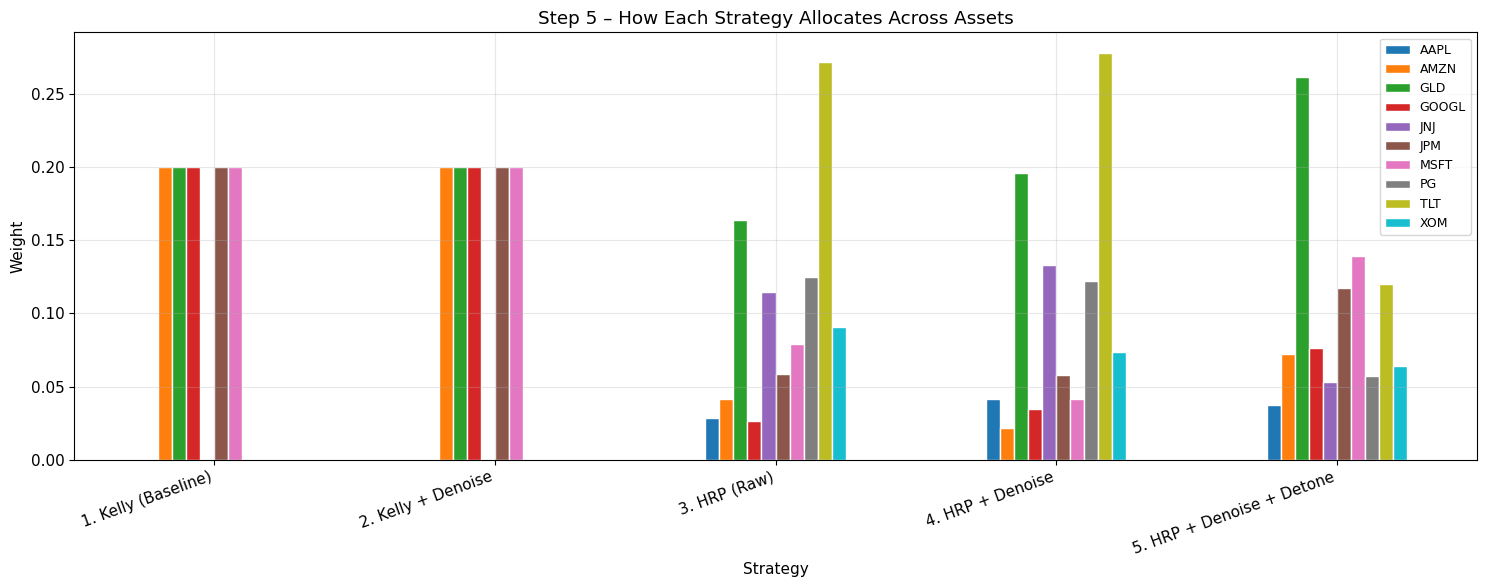

In [ ]:
ml_strats = {
    '1. Kelly (Baseline)'       : kelly_w,
    '2. Kelly + Denoise'        : kelly_opt(train_ret, cov_mat=cov_den, cap=0.20),
    '3. HRP (Raw)'              : hrp_raw_w,
    '4. HRP + Denoise'          : hrp_den_w,
    '5. HRP + Denoise + Detone' : hrp_det_w,
}

# Print the weight allocations so we can see how each strategy distributes capital
w_df = pd.DataFrame(ml_strats, index=train_ret.columns)
print('Portfolio Weights by Strategy:')
print(w_df.round(4).to_string())

# Side-by-side bar chart to compare allocations visually
w_df.T.plot(kind='bar', figsize=(15, 6), edgecolor='white')
plt.title('Step 5 – How Each Strategy Allocates Across Assets')
plt.xlabel('Strategy'); plt.ylabel('Weight')
plt.xticks(rotation=20, ha='right')
plt.legend(loc='upper right', fontsize=9)
plt.tight_layout(); plt.show()

---
## Step 6 – Do Multiple Improvements Actually Beat Single Improvements?

This is the key question for Step 6. We've applied the ML improvements to the training data — but do they actually translate into **better out-of-sample performance**? And does combining all three (denoise + detone + HRP) do better than using just one?

We'll evaluate all five strategies on the test period (Oct – Dec 2025) using five metrics: Cumulative Return, Sharpe Ratio, Sortino Ratio, Max Drawdown and 95% CVaR.

Out-of-Sample Performance: Single vs Multiple Improvements (Oct – Dec 2025)
                           Cum Return (%)  Sharpe Ratio  Sortino Ratio  Max Drawdown (%)  95% CVaR (%)
1. Kelly (Baseline)                  8.32        2.1055         3.3495             -5.31       -1.8312
2. Kelly + Denoise                   8.32        2.1055         3.3495             -5.31       -1.8312
3. HRP (Raw)                         4.05        2.3123         4.0365             -2.06       -0.7936
4. HRP + Denoise                     4.97        2.5815         3.9830             -2.54       -0.9062
5. HRP + Denoise + Detone            6.13        2.3580         3.2660             -3.21       -1.3288


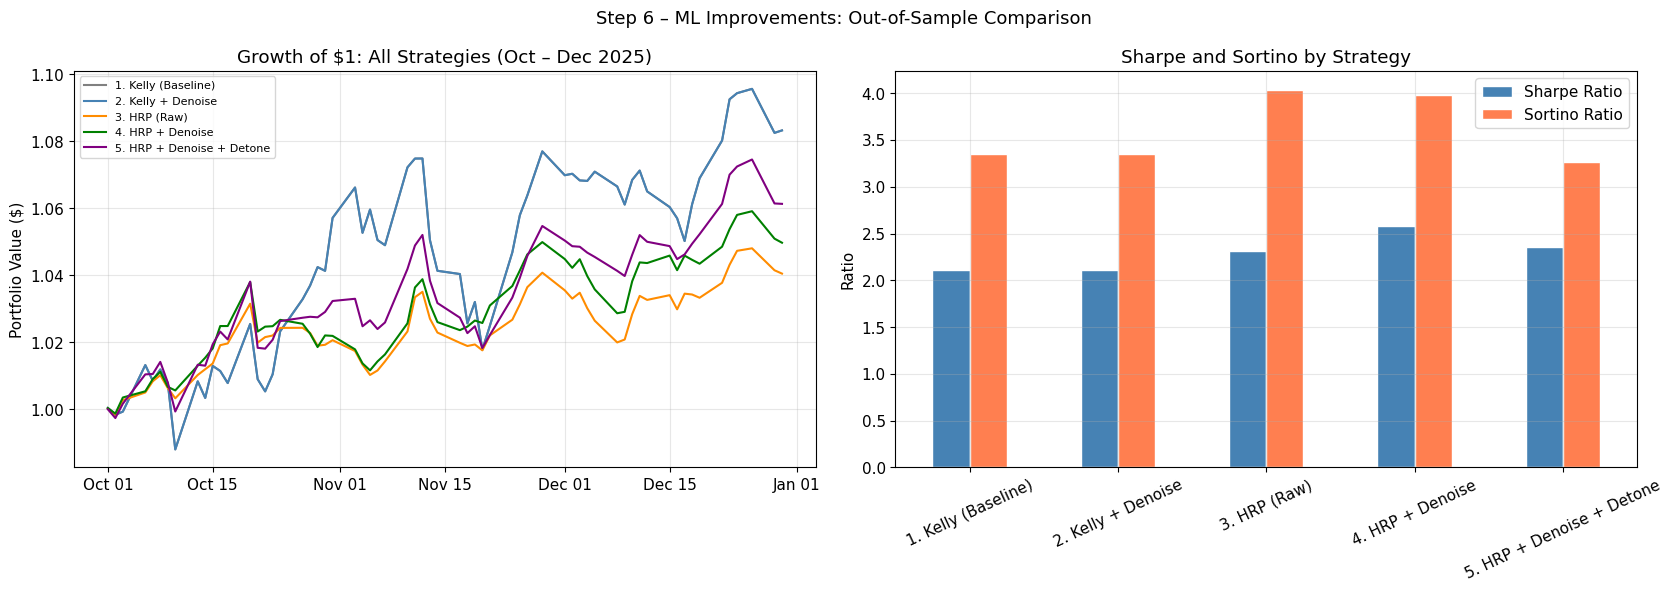

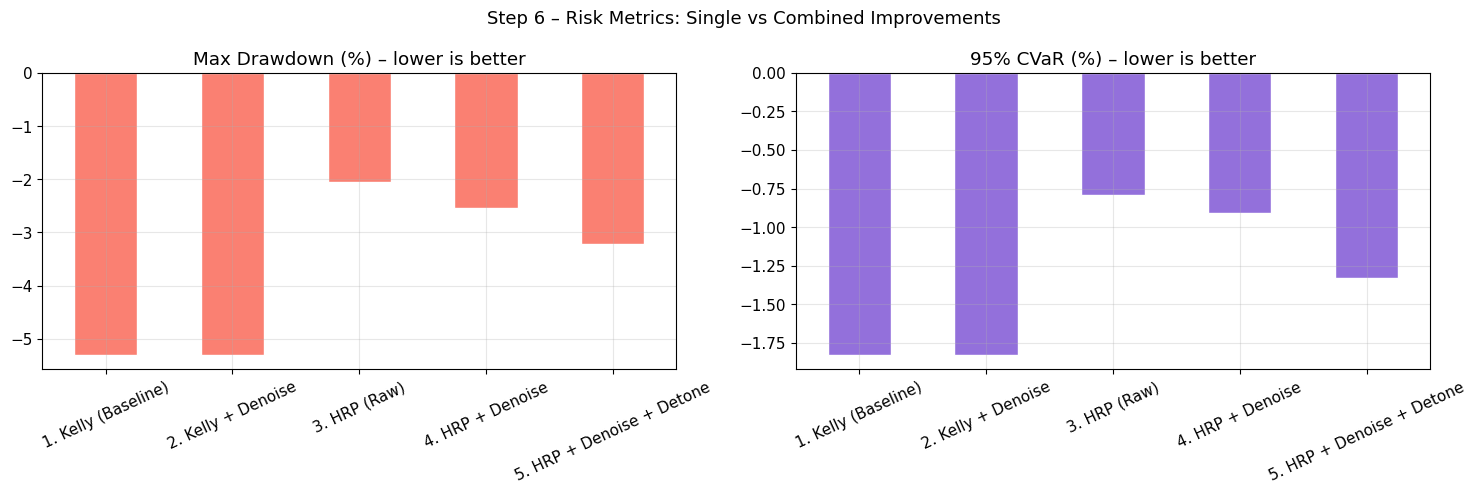

In [ ]:
# Build the full performance table for all five strategies
comp_table = score_table(ml_strats, test_ret)
print('Out-of-Sample Performance: Single vs Multiple Improvements (Oct – Dec 2025)')
print('=' * 70)
print(comp_table.to_string())

# Equity curves: see how each strategy grew over the test period
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
palette   = ['grey', 'steelblue', 'darkorange', 'green', 'purple']

for (name, w), c in zip(ml_strats.items(), palette):
    equity = np.exp(port_ret_series(w, test_ret).cumsum())
    axes[0].plot(equity.index, equity.values, label=name, color=c)
axes[0].set_title('Growth of $1: All Strategies (Oct – Dec 2025)')
axes[0].set_ylabel('Portfolio Value ($)'); axes[0].legend(fontsize=8)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

comp_table[['Sharpe Ratio', 'Sortino Ratio']].plot(kind='bar', ax=axes[1], color=['steelblue', 'coral'], edgecolor='white')
axes[1].set_title('Sharpe and Sortino by Strategy'); axes[1].set_ylabel('Ratio')
axes[1].tick_params(axis='x', rotation=25)

plt.suptitle('Step 6 – ML Improvements: Out-of-Sample Comparison', fontsize=13)
plt.tight_layout(); plt.show()

# Risk metrics: drawdown and CVaR
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
comp_table['Max Drawdown (%)'].plot(kind='bar', ax=axes[0], color='salmon', edgecolor='white')
axes[0].set_title('Max Drawdown (%) – lower is better'); axes[0].tick_params(axis='x', rotation=25)

comp_table['95% CVaR (%)'].plot(kind='bar', ax=axes[1], color='mediumpurple', edgecolor='white')
axes[1].set_title('95% CVaR (%) – lower is better'); axes[1].tick_params(axis='x', rotation=25)

plt.suptitle('Step 6 – Risk Metrics: Single vs Combined Improvements', fontsize=13)
plt.tight_layout(); plt.show()

---
## Step 7 – Technical Talk: The Problem of Estimation Error

### Slide 1 – Why Estimation Error Matters

Both MVO and the Kelly Criterion produce weights of the form $w^* = \Sigma^{-1}\mu$. This looks clean mathematically, but in practice both $\Sigma$ and $\mu$ are *estimated* from historical data. Every estimate contains error, and matrix inversion has a nasty habit of **amplifying** those errors. A small perturbation in $\Sigma$ can cause a large shift in $\Sigma^{-1}$, leading to wildly different portfolio weights from one period to the next.

### Slide 2 – The Mathematical Bound from RMT

Random Matrix Theory gives us a precise way to separate signal from noise in the covariance matrix. For a sample of $T$ observations of $N$ assets, the eigenvalues of a pure-noise correlation matrix concentrate within:
$$\lambda \in \left[\lambda^-, \lambda^+\right], \qquad \lambda^{\pm} = \left(1 \pm \sqrt{\frac{N}{T}}\right)^2$$
Eigenvalues above $\lambda^+$ carry genuine information about asset co-movements.

### Slide 3 – What This Means for Our Data

With $T = 459$ days and $N = 10$ assets, we get $q = N/T \approx 0.022$ and $\lambda^+ \approx 1.58$. In practice this means most of the eigenvalue spectrum is signal (since $q$ is small), but the few eigenvalues near the boundary are still worth cleaning up. The eigenvalue plot in Step 4 shows clearly how denoising smooths out the lower end of the spectrum.

### Slide 4 – How Each Method Responds

| Method | How it addresses estimation error |
|--------|----------------------------------|
| Denoising | Replaces noise eigenvalues → better-conditioned $\Sigma$ → more stable $\Sigma^{-1}$ |
| Detoning | Removes market eigenvector → HRP clusters assets more meaningfully |
| HRP | No matrix inversion at all → not affected by ill-conditioning |

### Slide 5 – What We Found

The rolling Sharpe chart below illustrates one of the key risks of estimation error: the Kelly baseline can swing dramatically period to period as the estimated $\Sigma^{-1}$ changes. The HRP + Denoise + Detone strategy tends to be more stable over time — not necessarily always higher, but more consistent, which matters a lot in real portfolio management where turnover costs money.

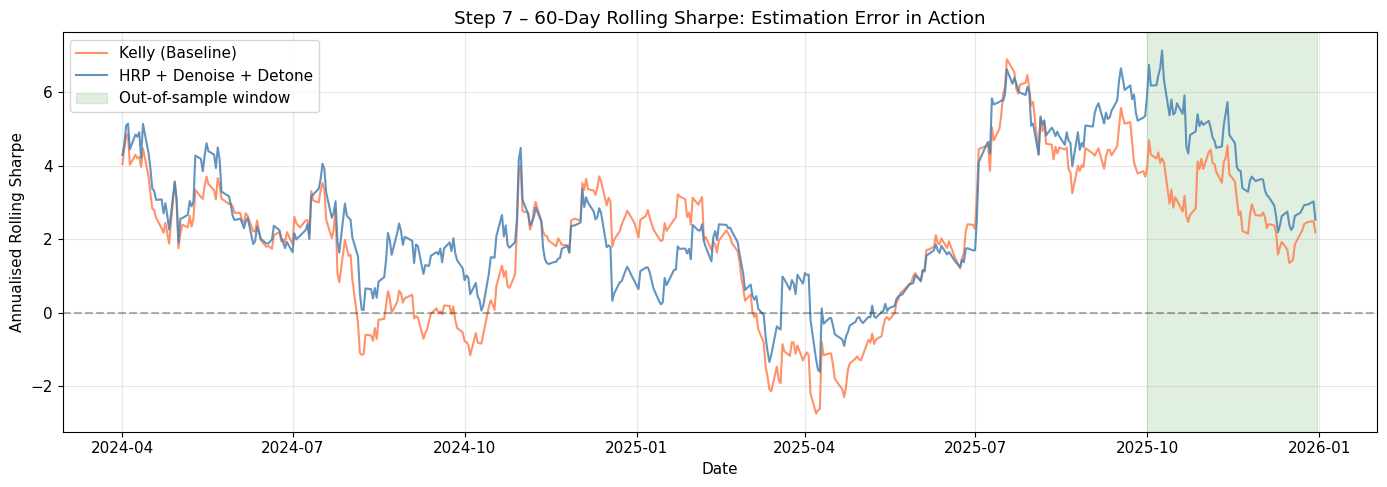

In [ ]:
# 60-day rolling Sharpe comparison: Kelly Baseline vs the best ML pipeline
WINDOW = 60
rolling_dates, r_kelly_sharpe, r_hrp_sharpe = [], [], []

for i in range(WINDOW, len(full_ret)):
    w_ret = full_ret.iloc[i - WINDOW:i]
    r_kelly_sharpe.append(sharpe(port_ret_series(kelly_w, w_ret)))
    r_hrp_sharpe.append(sharpe(port_ret_series(hrp_det_w, w_ret)))
    rolling_dates.append(full_ret.index[i])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(rolling_dates, r_kelly_sharpe, label='Kelly (Baseline)', color='coral',     alpha=0.85)
ax.plot(rolling_dates, r_hrp_sharpe,   label='HRP + Denoise + Detone', color='steelblue', alpha=0.85)
ax.axhline(0, linestyle='--', color='black', alpha=0.3)

# Shade the out-of-sample window so it's easy to see
ax.axvspan(pd.Timestamp('2025-10-01'), pd.Timestamp('2025-12-31'),
           alpha=0.12, color='green', label='Out-of-sample window')

ax.set_title('Step 7 – 60-Day Rolling Sharpe: Estimation Error in Action')
ax.set_xlabel('Date'); ax.set_ylabel('Annualised Rolling Sharpe')
ax.legend(); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.tight_layout(); plt.show()

print()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import yfinance as yf
from scipy.optimize import minimize
from scipy.stats import norm
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)


TICKERS    = ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM', 'XOM', 'JNJ', 'PG', 'GLD', 'TLT']
N          = len(TICKERS)
RF_ANNUAL  = 0.05
RF_DAILY   = RF_ANNUAL / 252
TRAIN_START = '2024-01-01'
TRAIN_END   = '2025-09-30'
TEST_START  = '2025-10-01'
TEST_END    = '2025-12-31'
FULL_START  = '2024-01-01'
FULL_END    = '2025-12-31'
MAX_WEIGHT  = 0.20
TRADING_DAYS = 252

print('Configuration loaded.')
print(f'Assets : {TICKERS}')
print(f'RF daily: {RF_DAILY*10000:.4f} bps')

Configuration loaded.
Assets : ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM', 'XOM', 'JNJ', 'PG', 'GLD', 'TLT']
RF daily: 1.9841 bps


In [ ]:
raw = yf.download(TICKERS, start=FULL_START, end=FULL_END,
                  auto_adjust=True, progress=False)['Close']
raw.dropna(how='all', inplace=True)
raw.ffill(inplace=True)

returns_full = np.log(raw / raw.shift(1)).dropna()

ret_train = returns_full[TRAIN_START:TRAIN_END]
ret_test  = returns_full[TEST_START:TEST_END]

print(f'Full returns shape  : {returns_full.shape}')
print(f'Training period     : {ret_train.index[0].date()} → {ret_train.index[-1].date()}  ({len(ret_train)} days)')
print(f'Out-of-sample period: {ret_test.index[0].date()} → {ret_test.index[-1].date()}  ({len(ret_test)} days)')

Full returns shape  : (500, 10)
Training period     : 2024-01-03 → 2025-09-30  (437 days)
Out-of-sample period: 2025-10-01 → 2025-12-30  (63 days)


In [ ]:
mu_daily  = ret_train.mean().values
cov_daily = ret_train.cov().values
mu_excess = mu_daily - RF_DAILY

cov_inv    = np.linalg.inv(cov_daily)
w_kelly_raw = cov_inv @ mu_excess

print('Unconstrained Kelly weights ')
for t, w in zip(TICKERS, w_kelly_raw):
    print(f'  {t:6s}: {w:+.4f}')
print(f'  Sum   : {w_kelly_raw.sum():.4f}  (leverage factor)')

def normalise(w):
    w = np.maximum(w, 0)
    return w / w.sum()

w_kelly_norm = normalise(w_kelly_raw)
print('\n Full-Kelly (normalised, long-only) ')
for t, w in zip(TICKERS, w_kelly_norm):
    if w > 1e-4:
        print(f'  {t:6s}: {w*100:.2f}%')

Unconstrained Kelly weights 
  AAPL  : +0.0578
  MSFT  : -0.8937
  AMZN  : +12.3706
  GOOGL : +1.7743
  JPM   : +1.9281
  XOM   : +5.8891
  JNJ   : +0.1950
  PG    : -0.7225
  GLD   : -4.7189
  TLT   : -2.7760
  Sum   : 13.1038  (leverage factor)

 Full-Kelly (normalised, long-only) 
  AAPL  : 0.26%
  AMZN  : 55.69%
  GOOGL : 7.99%
  JPM   : 8.68%
  XOM   : 26.51%
  JNJ   : 0.88%


In [ ]:
def neg_kelly_growth(w, mu, cov):
    return -(w @ mu - 0.5 * w @ cov @ w)

constraints = [
    {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
]
bounds = [(0, MAX_WEIGHT)] * N

w0 = np.ones(N) / N

res = minimize(
    neg_kelly_growth,
    w0,
    args=(mu_excess, cov_daily),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'ftol': 1e-12, 'maxiter': 1000}
)

assert res.success, f'Optimisation failed: {res.message}'
w_kelly_constrained = res.x

print('Constrained Kelly weights (long-only, max 20% cap) ')
for t, w in zip(TICKERS, w_kelly_constrained):
    print(f'  {t:6s}: {w*100:.2f}%')
print(f'  Sum   : {w_kelly_constrained.sum()*100:.2f}%')
print(f'  Max   : {w_kelly_constrained.max()*100:.2f}%  (cap = {MAX_WEIGHT*100:.0f}%)')


Constrained Kelly weights (long-only, max 20% cap) 
  AAPL  : 0.00%
  MSFT  : 20.00%
  AMZN  : 20.00%
  GOOGL : 20.00%
  JPM   : 0.00%
  XOM   : 20.00%
  JNJ   : 20.00%
  PG    : 0.00%
  GLD   : 0.00%
  TLT   : 0.00%
  Sum   : 100.00%
  Max   : 20.00%  (cap = 20%)


In [ ]:
w_half_kelly   = w_kelly_constrained * 0.5
w_double_kelly = w_kelly_constrained * 2.0


portfolios = {
    'Full-Kelly (unconstrained)' : w_kelly_norm,
    'Full-Kelly (constrained 20%)': w_kelly_constrained,
    'Half-Kelly'                 : w_half_kelly,
    'Double-Kelly'               : w_double_kelly,
}

weight_df = pd.DataFrame(portfolios, index=TICKERS) * 100
print('Portfolio Weights (%)')
print(weight_df.round(2).to_string())

Portfolio Weights (%)
       Full-Kelly (unconstrained)  Full-Kelly (constrained 20%)  Half-Kelly  Double-Kelly
AAPL                         0.26                           0.0         0.0           0.0
MSFT                         0.00                          20.0        10.0          40.0
AMZN                        55.69                          20.0        10.0          40.0
GOOGL                        7.99                          20.0        10.0          40.0
JPM                          8.68                           0.0         0.0           0.0
XOM                         26.51                          20.0        10.0          40.0
JNJ                          0.88                          20.0        10.0          40.0
PG                           0.00                           0.0         0.0           0.0
GLD                          0.00                           0.0         0.0           0.0
TLT                          0.00                           0.0         0.0   

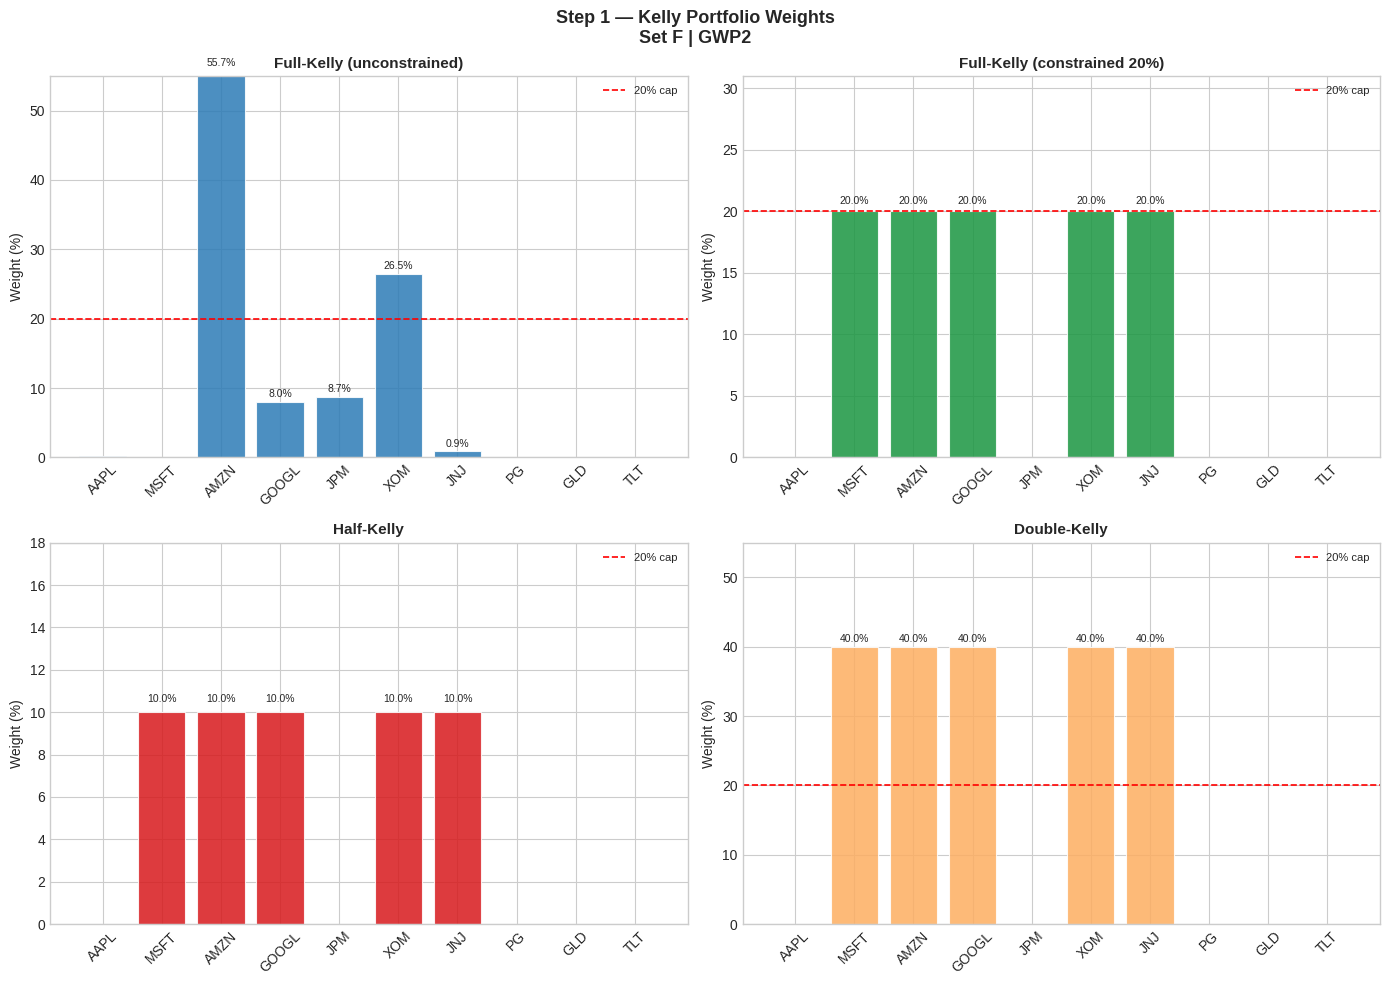

Chart saved as kelly_weights.png


In [ ]:
colors = ['#2c7bb6', '#1a9641', '#d7191c', '#fdae61']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (name, w), color in zip(axes, portfolios.items(), colors):
    bars = ax.bar(TICKERS, w * 100, color=color, alpha=0.85, edgecolor='white', linewidth=0.8)
    ax.axhline(20, color='red', linestyle='--', linewidth=1.2, label='20% cap')
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_ylabel('Weight (%)')
    ax.set_ylim(0, min(max(w*100)*1.3 + 5, 55))
    ax.tick_params(axis='x', rotation=45)
    ax.legend(fontsize=8)
    for bar, val in zip(bars, w*100):
        if val > 0.5:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
                    f'{val:.1f}%', ha='center', va='bottom', fontsize=7.5)

plt.suptitle('Step 1 — Kelly Portfolio Weights\nSet F | GWP2', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('kelly_weights.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as kelly_weights.png')

In [ ]:

print("In-Sample Kelly Growth Rate ")
for name, w in portfolios.items():
    g = w @ mu_excess - 0.5 * w @ cov_daily @ w
    print(f'  {name:35s}: {g*252*100:.2f}% ')

In-Sample Kelly Growth Rate 
  Full-Kelly (unconstrained)         : 28.00% 
  Full-Kelly (constrained 20%)       : 23.11% 
  Half-Kelly                         : 11.93% 
  Double-Kelly                       : 43.20% 


In [ ]:
def portfolio_returns(weights, ret_df):

    return ret_df.values @ weights

def cumulative_return(r):

    return np.exp(np.sum(r)) - 1

def sharpe_ratio(r, rf_daily=RF_DAILY, ann=TRADING_DAYS):

    excess = r - rf_daily
    if excess.std() == 0:
        return np.nan
    return (excess.mean() / excess.std()) * np.sqrt(ann)

def max_drawdown(r):

    cum = np.exp(np.cumsum(r))
    running_max = np.maximum.accumulate(cum)
    dd = (cum - running_max) / running_max
    return dd.min()

def cvar_95(r):

    q = np.percentile(r, 5)
    tail = r[r <= q]
    return -tail.mean() if len(tail) > 0 else np.nan

def compute_metrics(weights, ret_df, label=''):
    r = portfolio_returns(weights, ret_df)
    return {
        'Portfolio'          : label,
        'Cumulative Return'  : f'{cumulative_return(r)*100:.2f}%',
        'Sharpe Ratio'       : f'{sharpe_ratio(r):.4f}',
        'Max Drawdown'       : f'{max_drawdown(r)*100:.2f}%',
        '95% CVaR (daily)'   : f'{cvar_95(r)*100:.4f}%',
    }

print('Helper functions defined.')

Helper functions defined.


In [ ]:
results = []
for name, w in portfolios.items():
    results.append(compute_metrics(w, ret_test, label=name))

perf_df = pd.DataFrame(results).set_index('Portfolio')

print('Step 2: Out-of-Sample Performance (Oct 1 – Dec 31, 2025) ')
print(perf_df.to_string())

Step 2: Out-of-Sample Performance (Oct 1 – Dec 31, 2025) 
                             Cumulative Return Sharpe Ratio Max Drawdown 95% CVaR (daily)
Portfolio                                                                                
Full-Kelly (unconstrained)              10.77%       2.0209       -5.16%          2.5943%
Full-Kelly (constrained 20%)             8.32%       1.7906       -5.31%          1.8312%
Half-Kelly                               4.08%       1.4588       -2.69%          0.9156%
Double-Kelly                            17.34%       1.9566      -10.33%          3.6624%


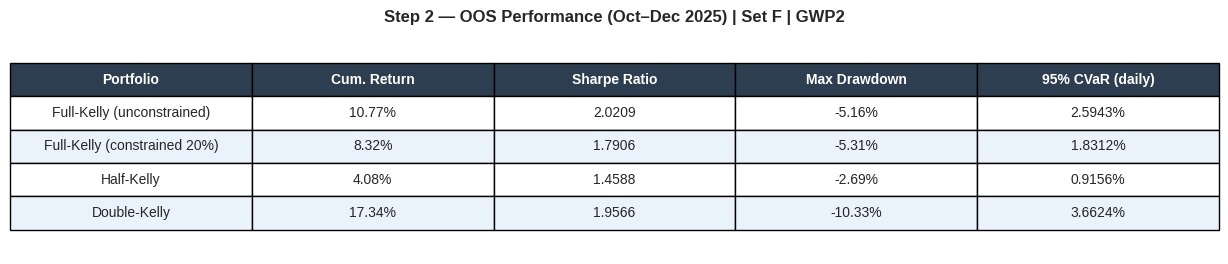

In [ ]:
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.axis('off')

col_labels = ['Portfolio', 'Cum. Return', 'Sharpe Ratio', 'Max Drawdown', '95% CVaR (daily)']
table_data = [[idx] + list(row) for idx, row in zip(perf_df.index, perf_df.values)]

tbl = ax.table(
    cellText=table_data,
    colLabels=col_labels,
    loc='center',
    cellLoc='center'
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1.2, 2.0)

# Header styling
for j in range(len(col_labels)):
    tbl[0, j].set_facecolor('#2c3e50')
    tbl[0, j].set_text_props(color='white', fontweight='bold')

# Alternating row colours
for i in range(1, len(table_data)+1):
    for j in range(len(col_labels)):
        tbl[i, j].set_facecolor('#eaf2fb' if i % 2 == 0 else 'white')

plt.title('Step 2 — OOS Performance (Oct–Dec 2025) | Set F | GWP2',
          fontsize=12, fontweight='bold', pad=12)
plt.savefig('oos_performance_table.png', dpi=150, bbox_inches='tight')
plt.show()

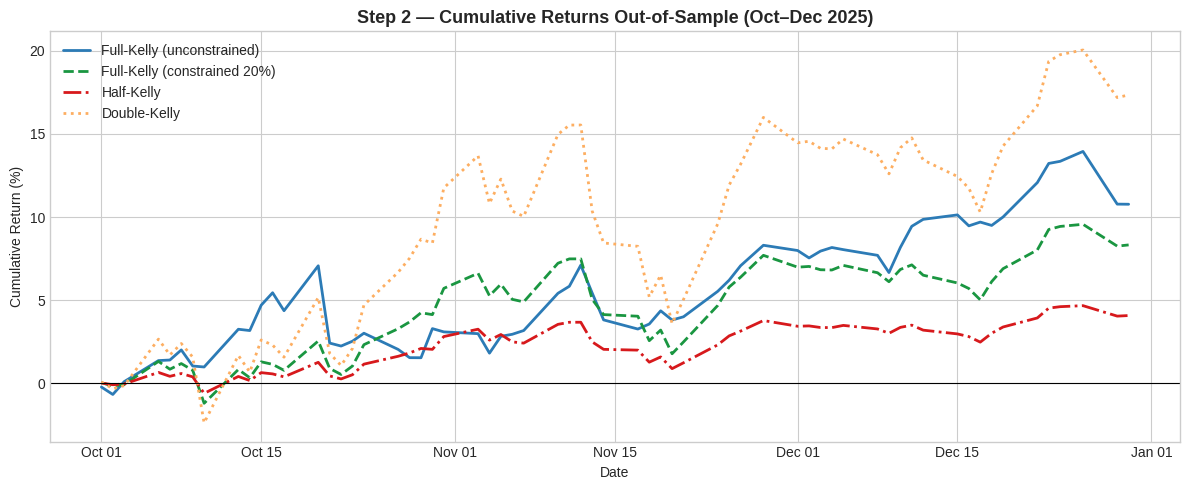

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
colors_plot = ['#2c7bb6', '#1a9641', '#d7191c', '#fdae61']
styles      = ['-', '--', '-.', ':']

for (name, w), col, ls in zip(portfolios.items(), colors_plot, styles):
    r   = portfolio_returns(w, ret_test)
    cum = (np.exp(np.cumsum(r)) - 1) * 100
    ax.plot(ret_test.index, cum, label=name, color=col, linestyle=ls, linewidth=2)

ax.axhline(0, color='black', linewidth=0.8, linestyle='-')
ax.set_title('Step 2 — Cumulative Returns Out-of-Sample (Oct–Dec 2025)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Cumulative Return (%)')
ax.set_xlabel('Date')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('oos_cumulative_returns.png', dpi=150, bbox_inches='tight')
plt.show()


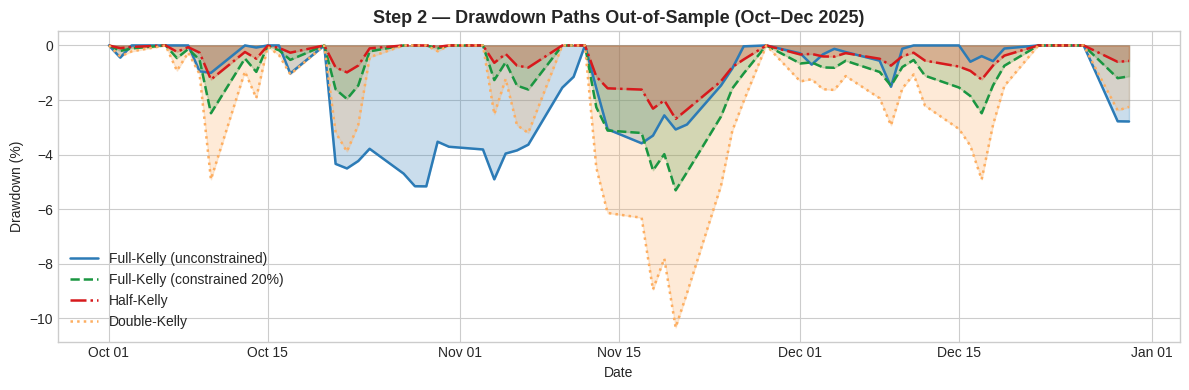

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))

for (name, w), col, ls in zip(portfolios.items(), colors_plot, styles):
    r   = portfolio_returns(w, ret_test)
    cum = np.exp(np.cumsum(r))
    running_max = np.maximum.accumulate(cum)
    dd  = (cum - running_max) / running_max * 100
    ax.fill_between(ret_test.index, dd, 0, alpha=0.25, color=col)
    ax.plot(ret_test.index, dd, label=name, color=col, linestyle=ls, linewidth=1.8)

ax.set_title('Step 2 — Drawdown Paths Out-of-Sample (Oct–Dec 2025)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Drawdown (%)')
ax.set_xlabel('Date')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('oos_drawdowns.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
K = 5
T = len(returns_full)
fold_size = T // K


fold_boundaries = [(i * fold_size, (i+1) * fold_size) for i in range(K)]

fold_boundaries[-1] = (fold_boundaries[-1][0], T)

print(f'Total trading days : {T}')
print(f'Number of folds K  : {K}')
print(f'Approximate fold size: {fold_size} days')
print('\nFold date ranges:')
for i, (s, e) in enumerate(fold_boundaries):
    d_start = returns_full.index[s].date()
    d_end   = returns_full.index[e-1].date()
    print(f'  Fold {i+1}: {d_start} → {d_end}  ({e-s} days)')

Total trading days : 500
Number of folds K  : 5
Approximate fold size: 100 days

Fold date ranges:
  Fold 1: 2024-01-03 → 2024-05-24  (100 days)
  Fold 2: 2024-05-28 → 2024-10-17  (100 days)
  Fold 3: 2024-10-18 → 2025-03-14  (100 days)
  Fold 4: 2025-03-17 → 2025-08-07  (100 days)
  Fold 5: 2025-08-08 → 2025-12-30  (100 days)


In [ ]:
import numpy as np


def fit_kelly_constrained(ret_df):
    """Fit constrained Kelly weights (long-only, max 20%, sums to 1)."""
    mu  = ret_df.mean().values - RF_DAILY
    cov = ret_df.cov().values
    res = minimize(
        neg_kelly_growth, np.ones(N)/N, args=(mu, cov),
        method='SLSQP',
        bounds=[(0, MAX_WEIGHT)]*N,
        constraints=[{'type':'eq','fun': lambda w: np.sum(w)-1}],
        options={'ftol':1e-12,'maxiter':1000}
    )
    return res.x if res.success else np.ones(N)/N

def fit_kelly_raw(ret_df):
    """Fit normalised unconstrained Kelly weights (long-only, sums to 1)."""
    mu  = ret_df.mean().values - RF_DAILY
    cov = ret_df.cov().values
    w   = np.linalg.inv(cov) @ mu
    return normalise(w)


kfold_strategies = {
    'Full-Kelly (constrained 20%)': (fit_kelly_constrained, 1.0),
    'Full-Kelly (unconstrained)'  : (fit_kelly_raw,         1.0),
    'Half-Kelly'                  : (fit_kelly_constrained, 0.5),
    'Double-Kelly'                : (fit_kelly_constrained, 2.0),
}

kfold_records = {name: [] for name in kfold_strategies}

for k in range(1, K):
    train_start = fold_boundaries[0][0]
    train_end   = fold_boundaries[k][0]
    val_start   = fold_boundaries[k][0]
    val_end     = fold_boundaries[k][1]

    ret_tr  = returns_full.iloc[train_start:train_end]
    ret_val = returns_full.iloc[val_start:val_end]

    d0_tr  = returns_full.index[train_start].date()
    d1_tr  = returns_full.index[train_end-1].date()
    d0_val = returns_full.index[val_start].date()
    d1_val = returns_full.index[val_end-1].date()
    print(f'\nFold {k+1}  |  Train: {d0_tr}→{d1_tr} ({len(ret_tr)}d)  |  '
          f'Val: {d0_val}→{d1_val} ({len(ret_val)}d)')

    for name, (fit_fn, lev) in kfold_strategies.items():
        w = fit_fn(ret_tr)
        r = portfolio_returns(w, ret_val) * lev
        rec = {
            'Fold'             : k+1,
            'Train Start'      : d0_tr,
            'Train End'        : d1_tr,
            'Val Start'        : d0_val,
            'Val End'          : d1_val,
            'Cumulative Return': cumulative_return(r) * 100,
            'Sharpe Ratio'     : sharpe_ratio(r),
            'Max Drawdown'     : max_drawdown(r) * 100,
            '95% CVaR (daily)' : cvar_95(r) * 100,
        }
        kfold_records[name].append(rec)
        print(f'  {name:35s}  CumRet={rec["Cumulative Return"]:+6.2f}%  '
              f'Sharpe={rec["Sharpe Ratio"]:+.3f}  '
              f'MDD={rec["Max Drawdown"]:+.2f}%')


Fold 2  |  Train: 2024-01-03→2024-05-24 (100d)  |  Val: 2024-05-28→2024-10-17 (100d)
  Full-Kelly (constrained 20%)         CumRet= +4.13%  Sharpe=+0.339  MDD=-11.55%
  Full-Kelly (unconstrained)           CumRet= +6.93%  Sharpe=+1.312  MDD=-4.81%
  Half-Kelly                           CumRet= +2.04%  Sharpe=+0.013  MDD=-5.95%
  Double-Kelly                         CumRet= +8.43%  Sharpe=+0.502  MDD=-21.77%

Fold 3  |  Train: 2024-01-03→2024-10-17 (200d)  |  Val: 2024-10-18→2025-03-14 (100d)
  Full-Kelly (constrained 20%)         CumRet= +1.18%  Sharpe=-0.158  MDD=-9.98%
  Full-Kelly (unconstrained)           CumRet= +3.17%  Sharpe=+0.278  MDD=-4.91%
  Half-Kelly                           CumRet= +0.59%  Sharpe=-0.546  MDD=-5.12%
  Double-Kelly                         CumRet= +2.38%  Sharpe=+0.036  MDD=-18.96%

Fold 4  |  Train: 2024-01-03→2025-03-14 (300d)  |  Val: 2025-03-17→2025-08-07 (100d)
  Full-Kelly (constrained 20%)         CumRet=+11.99%  Sharpe=+1.219  MDD=-10.08%
  Full-Ke

In [ ]:
metrics_list = ['Cumulative Return', 'Sharpe Ratio', 'Max Drawdown', '95% CVaR (daily)']
units        = ['%', '', '%', '%']

summary_rows = []
for name, records in kfold_records.items():
    df_rec = pd.DataFrame(records)
    row = {'Strategy': name}
    for m, u in zip(metrics_list, units):
        mean_val = df_rec[m].mean()
        std_val  = df_rec[m].std()
        row[m]   = f'{mean_val:.3f}{u} ± {std_val:.3f}{u}'
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index('Strategy')
print('Step 3: K-Fold Cross-Validation Summary (K=5, Time-Series)')
print(f'Mean ± Std across {K-1} validation folds')
print()
print(summary_df.to_string())

Step 3: K-Fold Cross-Validation Summary (K=5, Time-Series)
Mean ± Std across 4 validation folds

                              Cumulative Return   Sharpe Ratio       Max Drawdown 95% CVaR (daily)
Strategy                                                                                          
Full-Kelly (constrained 20%)    8.751% ± 7.512%  0.998 ± 1.207   -9.230% ± 2.712%  2.323% ± 0.604%
Full-Kelly (unconstrained)      9.836% ± 6.915%  1.378 ± 0.997   -5.876% ± 1.677%  1.850% ± 0.469%
Half-Kelly                      4.237% ± 3.593%  0.665 ± 1.217   -4.735% ± 1.415%  1.161% ± 0.302%
Double-Kelly                  18.690% ± 16.438%  1.165 ± 1.202  -17.554% ± 4.981%  4.646% ± 1.207%


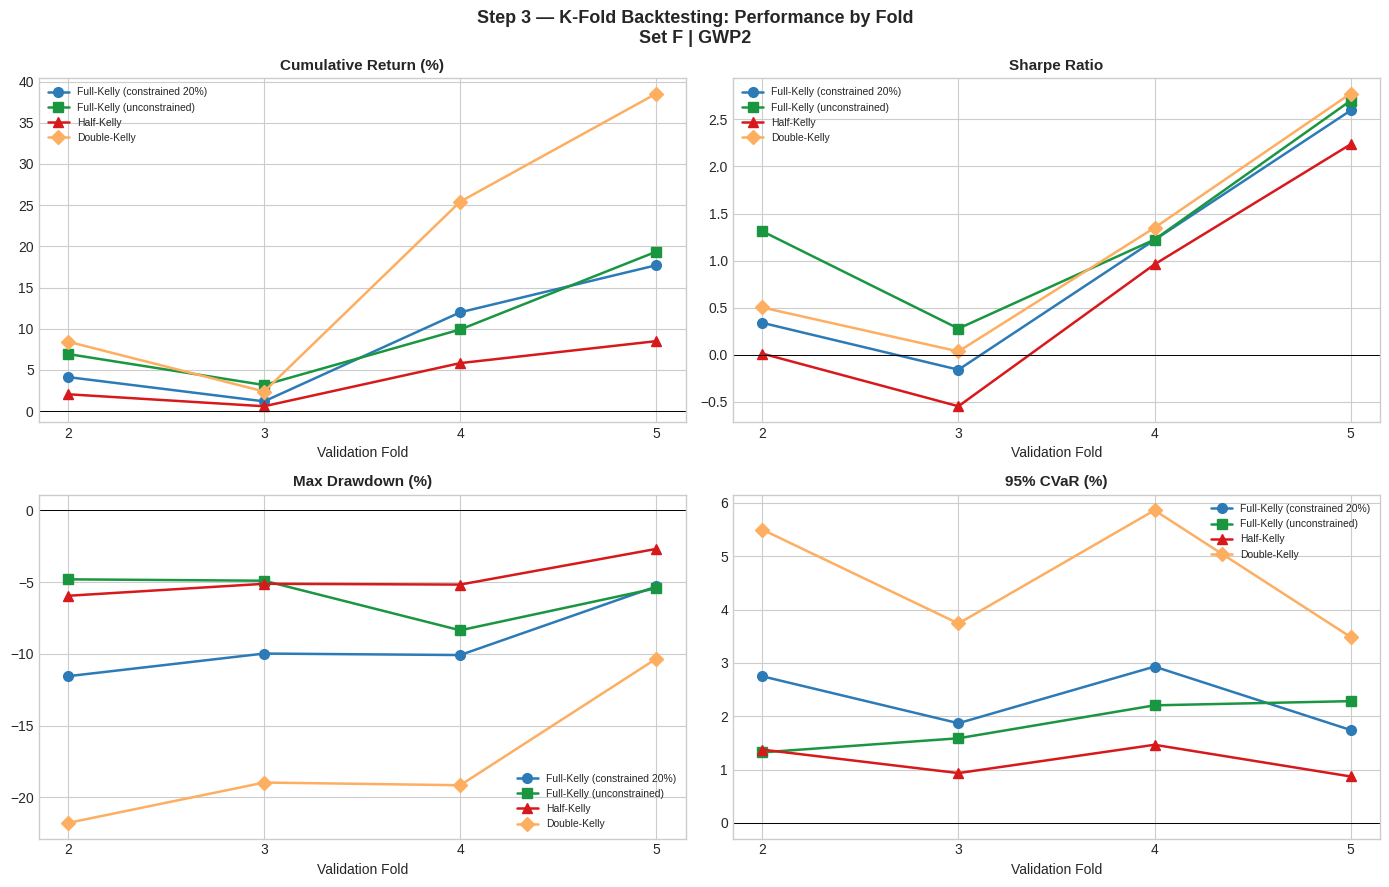

Chart saved as kfold_metrics.png


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()
metric_labels = ['Cumulative Return (%)', 'Sharpe Ratio',
                 'Max Drawdown (%)', '95% CVaR (%)']
metric_keys   = ['Cumulative Return', 'Sharpe Ratio', 'Max Drawdown', '95% CVaR (daily)']

colors_kf = ['#2c7bb6','#1a9641','#d7191c','#fdae61']
markers   = ['o','s','^','D']

for ax, (mkey, mlabel) in zip(axes, zip(metric_keys, metric_labels)):
    for (name, records), col, mk in zip(kfold_records.items(), colors_kf, markers):
        df_rec = pd.DataFrame(records)
        ax.plot(df_rec['Fold'], df_rec[mkey], label=name,
                color=col, marker=mk, linewidth=1.8, markersize=7)
    ax.set_title(mlabel, fontsize=11, fontweight='bold')
    ax.set_xlabel('Validation Fold')
    ax.set_xticks(range(2, K+1))
    ax.axhline(0, color='black', linewidth=0.7)
    ax.legend(fontsize=7.5)

plt.suptitle('Step 3 — K-Fold Backtesting: Performance by Fold\nSet F | GWP2',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('kfold_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as kfold_metrics.png')

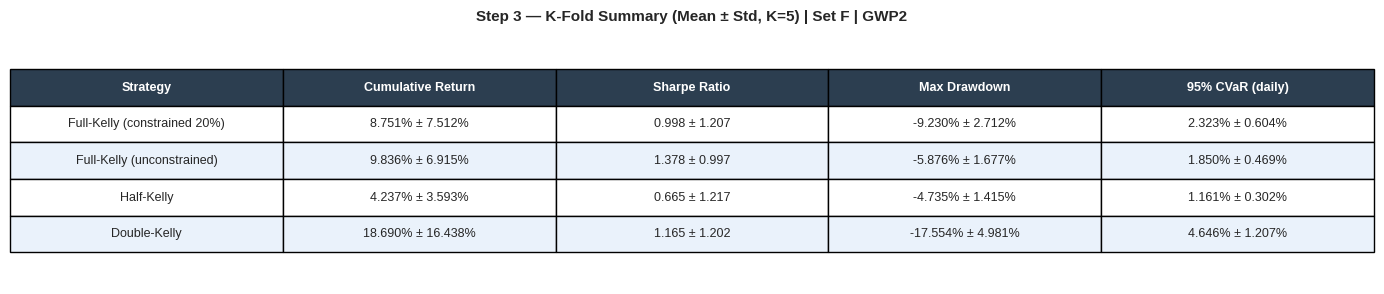

In [ ]:
fig, ax = plt.subplots(figsize=(16, 3.2))
ax.axis('off')

col_labels_kf = ['Strategy'] + list(summary_df.columns)
table_data_kf = [[idx] + list(row) for idx, row in zip(summary_df.index, summary_df.values)]

tbl2 = ax.table(
    cellText=table_data_kf,
    colLabels=col_labels_kf,
    loc='center',
    cellLoc='center'
)
tbl2.auto_set_font_size(False)
tbl2.set_fontsize(9)
tbl2.scale(1.1, 2.2)

for j in range(len(col_labels_kf)):
    tbl2[0, j].set_facecolor('#2c3e50')
    tbl2[0, j].set_text_props(color='white', fontweight='bold')

for i in range(1, len(table_data_kf)+1):
    for j in range(len(col_labels_kf)):
        tbl2[i, j].set_facecolor('#eaf2fb' if i % 2 == 0 else 'white')

plt.title('Step 3 — K-Fold Summary (Mean ± Std, K=5) | Set F | GWP2',
          fontsize=11, fontweight='bold', pad=12)
plt.savefig('kfold_summary_table.png', dpi=150, bbox_inches='tight')
plt.show()

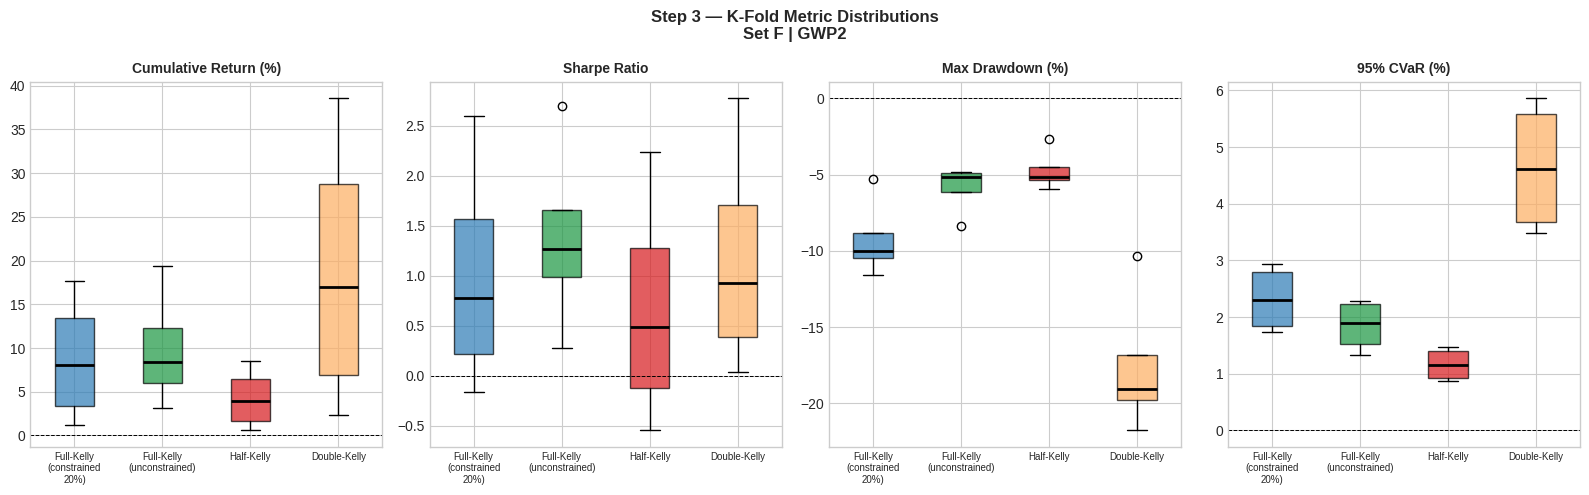

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, (mkey, mlabel) in zip(axes, zip(metric_keys, metric_labels)):
    data  = []
    names = []
    for name, records in kfold_records.items():
        data.append(pd.DataFrame(records)[mkey].values)
        names.append(name.replace(' ', '\n'))
    bp = ax.boxplot(data, patch_artist=True, notch=False,
                    medianprops={'color':'black','linewidth':2})
    for patch, col in zip(bp['boxes'], colors_kf):
        patch.set_facecolor(col)
        patch.set_alpha(0.7)
    ax.set_xticks(range(1, len(names)+1))
    ax.set_xticklabels(names, fontsize=7)
    ax.set_title(mlabel, fontsize=10, fontweight='bold')
    ax.axhline(0, color='black', linewidth=0.7, linestyle='--')

plt.suptitle('Step 3 — K-Fold Metric Distributions\nSet F | GWP2',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('kfold_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Tickers=['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM', 'XOM', 'JNJ', 'PG', 'GLD', 'TLT']
# Step 3 — K-fold cross-validation backtest for:
#   1) Kelly portfolio (20% cap)
#   2) Double-Kelly portfolio

import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import minimize

# Inputs
tickers = ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM', 'XOM', 'JNJ', 'PG', 'GLD', 'TLT']

start_date = '2024-01-01'
end_date   = '2025-12-31'

rf_annual = 0.05
rf_daily = rf_annual / 252

n_folds = 5
embargo_days = 5

# Download data
prices = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)['Close']
returns = prices.pct_change().dropna()

# Kelly optimization (20% cap)
def neg_kelly_objective(w, R, rf_daily):
    gross = 1 + rf_daily + R @ w
    if np.any(gross <= 0):
        return 1e10
    return -np.mean(np.log(gross))
def fit_kelly_capped(train_returns, rf_daily, cap=0.20):
    n = train_returns.shape[1]
    R = train_returns.values

    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]
    bounds = [(0.0, cap) for _ in range(n)]
    w0 = np.repeat(1 / n, n)

    result = minimize(
        neg_kelly_objective,
        w0,
        args=(R, rf_daily),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )

    if not result.success:
        raise ValueError(f"Optimization failed: {result.message}")

    return pd.Series(result.x, index=train_returns.columns, name='Kelly')

# Portfolio return engine
def portfolio_returns(asset_returns, risky_weights, rf_daily):
    risky_weights = risky_weights.reindex(asset_returns.columns)
    cash_weight = 1.0 - risky_weights.sum()
    port_ret = asset_returns @ risky_weights + cash_weight * rf_daily
    return pd.Series(port_ret, index=asset_returns.index)

# Metrics
def cumulative_return(r):
    return (1 + r).prod() - 1

def sharpe_ratio(r, rf_daily, annualization=252):
    excess = r - rf_daily
    vol = excess.std(ddof=1)
    if vol == 0 or np.isnan(vol):
        return np.nan
    return np.sqrt(annualization) * excess.mean() / vol

def max_drawdown(r):
    wealth = (1 + r).cumprod()
    running_max = wealth.cummax()
    dd = wealth / running_max - 1
    return dd.min()

def cvar_95(r):
    var_95 = np.quantile(r, 0.05)
    tail = r[r <= var_95]
    return tail.mean() if len(tail) > 0 else np.nan

def evaluate_strategy(r, rf_daily):
    return {
        'Cumulative Return': cumulative_return(r),
        'Sharpe Ratio': sharpe_ratio(r, rf_daily),
        'Maximum Drawdown': max_drawdown(r),
        '95%-cVaR': cvar_95(r)
    }

def generate_time_folds(index, n_folds=5, embargo_days=0):
    n = len(index)
    fold_sizes = np.full(n_folds, n // n_folds)
    fold_sizes[: n % n_folds] += 1

    folds = []
    start = 0
    for fold_size in fold_sizes:
        stop = start + fold_size
        test_idx = np.arange(start, stop)

        train_mask = np.ones(n, dtype=bool)
        embargo_start = max(0, start - embargo_days)
        embargo_stop  = min(n, stop + embargo_days)
        train_mask[embargo_start:embargo_stop] = False

        train_idx = np.arange(n)[train_mask]
        folds.append((train_idx, test_idx))
        start = stop

    return folds

folds = generate_time_folds(returns.index, n_folds=n_folds, embargo_days=embargo_days)

# Cross-validation loop
fold_results = []

for fold_num, (train_idx, test_idx) in enumerate(folds, start=1):
    train_returns = returns.iloc[train_idx]
    test_returns  = returns.iloc[test_idx]

    # Fit Kelly on training fold
    kelly_w = fit_kelly_capped(train_returns, rf_daily, cap=0.20)
    double_kelly_w = 2.0 * kelly_w

    # Test-fold portfolio returns
    kelly_test = portfolio_returns(test_returns, kelly_w, rf_daily)
    double_kelly_test = portfolio_returns(test_returns, double_kelly_w, rf_daily)

    # Metrics
    kelly_metrics = evaluate_strategy(kelly_test, rf_daily)
    dk_metrics = evaluate_strategy(double_kelly_test, rf_daily)

    for strategy_name, metrics_dict, weights in [
        ('Kelly', kelly_metrics, kelly_w),
        ('Double-Kelly', dk_metrics, double_kelly_w)
    ]:
        row = {
            'Fold': fold_num,
            'Strategy': strategy_name,
            'Train Start': train_returns.index.min(),
            'Train End': train_returns.index.max(),
            'Test Start': test_returns.index.min(),
            'Test End': test_returns.index.max(),
            'Weight Sum': weights.sum()
        }
        row.update(metrics_dict)
        fold_results.append(row)

cv_results = pd.DataFrame(fold_results)

# Aggregation of findings
summary_mean = cv_results.groupby('Strategy')[
    ['Cumulative Return', 'Sharpe Ratio', 'Maximum Drawdown', '95%-cVaR']
].mean()

summary_std = cv_results.groupby('Strategy')[
    ['Cumulative Return', 'Sharpe Ratio', 'Maximum Drawdown', '95%-cVaR']
].std()

# summary table
summary_table = pd.DataFrame(index=summary_mean.index)
for col in summary_mean.columns:
    summary_table[col] = summary_mean[col].round(6).astype(str) + "  (std=" + summary_std[col].round(6).astype(str) + ")"

# fold-level display
fold_display = cv_results.copy()
for col in ['Cumulative Return', 'Maximum Drawdown', '95%-cVaR']:
    fold_display[col] = fold_display[col].map(lambda x: f"{x:.2%}" if pd.notnull(x) else "NaN")
fold_display['Sharpe Ratio'] = fold_display['Sharpe Ratio'].map(lambda x: f"{x:.4f}" if pd.notnull(x) else "NaN")
fold_display['Weight Sum'] = fold_display['Weight Sum'].map(lambda x: f"{x:.4f}")

summary_display = summary_table.copy()

# Optional: cleaner percentage formatting in separate summary object
summary_mean_fmt = summary_mean.copy()
summary_std_fmt = summary_std.copy()
for col in ['Cumulative Return', 'Maximum Drawdown', '95%-cVaR']:
    summary_mean_fmt[col] = summary_mean_fmt[col].map(lambda x: f"{x:.2%}")
    summary_std_fmt[col] = summary_std_fmt[col].map(lambda x: f"{x:.2%}")
summary_mean_fmt['Sharpe Ratio'] = summary_mean_fmt['Sharpe Ratio'].map(lambda x: f"{x:.4f}")
summary_std_fmt['Sharpe Ratio'] = summary_std_fmt['Sharpe Ratio'].map(lambda x: f"{x:.4f}")

# -----------------------------
# Report
# -----------------------------
print("\n================ Fold-by-fold results ================\n")
print(fold_display[['Fold', 'Strategy', 'Train Start', 'Train End', 'Test Start', 'Test End',
                    'Weight Sum', 'Cumulative Return', 'Sharpe Ratio', 'Maximum Drawdown', '95%-cVaR']])

print("\n================ Cross-validation summary (mean across folds) ================\n")
print(summary_mean_fmt)

[*********************100%***********************]  10 of 10 completed



================ Fold-by-fold results ================

   Fold      Strategy Train Start  Train End Test Start   Test End Weight Sum  \
0     1         Kelly  2024-06-04 2025-12-30 2024-01-03 2024-05-24     1.0000   
1     1  Double-Kelly  2024-06-04 2025-12-30 2024-01-03 2024-05-24     2.0000   
2     2         Kelly  2024-01-03 2025-12-30 2024-05-28 2024-10-17     1.0000   
3     2  Double-Kelly  2024-01-03 2025-12-30 2024-05-28 2024-10-17     2.0000   
4     3         Kelly  2024-01-03 2025-12-30 2024-10-18 2025-03-14     1.0000   
5     3  Double-Kelly  2024-01-03 2025-12-30 2024-10-18 2025-03-14     2.0000   
6     4         Kelly  2024-01-03 2025-12-30 2025-03-17 2025-08-07     1.0000   
7     4  Double-Kelly  2024-01-03 2025-12-30 2025-03-17 2025-08-07     2.0000   
8     5         Kelly  2024-01-03 2025-07-31 2025-08-08 2025-12-30     1.0000   
9     5  Double-Kelly  2024-01-03 2025-07-31 2025-08-08 2025-12-30     2.0000   

  Cumulative Return Sharpe Ratio Maximum Drawdown 9

In [ ]:
# ------------------------------------------------------------------
# GWP2 — Application of the Three Improvements to the Same 10 Assets
#   1) Denoising  -> Denoised Kelly portfolio
#   2) Clustering -> HRP portfolio
#   3) Detoning   -> Detoned Kelly portfolio
# Assets:
#   ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM', 'XOM', 'JNJ', 'PG', 'GLD', 'TLT']
# In-sample  : 2024-01-01 to 2025-09-30
# Out-of-sample: 2025-10-01 to 2025-12-31
# -----------------------------------------------------------------

import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import minimize
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

# Data download data

tickers = ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM', 'XOM', 'JNJ', 'PG', 'GLD', 'TLT']

train_start = '2024-01-01'
train_end   = '2025-09-30'
test_start  = '2025-10-01'
test_end    = '2025-12-31'

rf_annual = 0.05
rf_daily = rf_annual / 252

prices_train = yf.download(tickers, start=train_start, end=train_end, auto_adjust=True)['Close']
prices_test  = yf.download(tickers, start=test_start,  end=test_end,  auto_adjust=True)['Close']

returns_train = prices_train.pct_change().dropna()
returns_test  = prices_test.pct_change().dropna()

mu = returns_train.mean().values
cov = returns_train.cov().values
corr = returns_train.corr().values
std = returns_train.std().values
assets = returns_train.columns.tolist()

# Helper functions

def cov2corr(cov):
    std = np.sqrt(np.diag(cov))
    corr = cov / np.outer(std, std)
    corr[corr < -1] = -1
    corr[corr > 1] = 1
    return corr

def corr2cov(corr, std):
    return corr * np.outer(std, std)

def get_pca(matrix):
    eigvals, eigvecs = np.linalg.eigh(matrix)
    idx = eigvals.argsort()[::-1]
    eigvals = eigvals[idx]
    eigvecs = eigvecs[:, idx]
    return eigvals, eigvecs

# a- Denoising (CREM-style)
def denoise_corr_crem(corr, T, N):
    """
    Constant Residual Eigenvalue Method (simple implementation).
    Uses Marcenko-Pastur upper bound to identify noise eigenvalues.
    q = T / N
    lambda_max = (1 + 1/sqrt(q))^2
    """
    eigvals, eigvecs = get_pca(corr)
    q = T / N
    lambda_max = (1 + 1 / np.sqrt(q))**2

    n_facts = np.sum(eigvals > lambda_max)
    n_facts = max(1, int(n_facts))  # keep at least one signal eigenvalue

    eigvals_d = eigvals.copy()
    if n_facts < len(eigvals_d):
        avg_noise = eigvals_d[n_facts:].mean()
        eigvals_d[n_facts:] = avg_noise

    corr_d = eigvecs @ np.diag(eigvals_d) @ eigvecs.T
    corr_d = cov2corr(corr_d)
    return corr_d, eigvals, eigvecs, n_facts

# b-Detoning
def detone_corr(corr_d, eigvals, eigvecs, market_components=1):
    """
    Remove the first principal component (market mode) from a denoised correlation matrix.
    """
    eigvals_mark = np.diag(eigvals[:market_components])
    eigvecs_mark = eigvecs[:, :market_components]
    corr_mark = eigvecs_mark @ eigvals_mark @ eigvecs_mark.T
    corr_dt = corr_d - corr_mark
    corr_dt = cov2corr(corr_dt)
    return corr_dt

# c) Kelly optimizer using the multivariate Kelly approximation
def solve_constrained_kelly(mu, cov, rf_daily, cap=0.20):
    n = len(mu)

    def objective(w):
        term1 = ((mu - rf_daily) @ w) / (1 + rf_daily)
        term2 = 0.5 * (w @ cov @ w) / (1 + rf_daily)**2
        return -(term1 - term2)

    cons = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]
    bounds = [(0.0, cap) for _ in range(n)]
    w0 = np.repeat(1/n, n)

    res = minimize(objective, w0, method='SLSQP', bounds=bounds, constraints=cons)
    if not res.success:
        raise ValueError(f"Kelly optimization failed: {res.message}")
    return pd.Series(res.x, index=assets)

# d) HRP (Hierarchical Risk Parity)
def correl_dist(corr):
    return np.sqrt((1 - corr) / 2)

def get_quasi_diag(link):
    return leaves_list(link)

def get_cluster_var(cov_df, cluster_items):
    cov_slice = cov_df.loc[cluster_items, cluster_items]
    ivp = 1 / np.diag(cov_slice.values)
    ivp /= ivp.sum()
    w = ivp.reshape(-1, 1)
    cluster_var = float(w.T @ cov_slice.values @ w)
    return cluster_var

def hrp_allocation(cov_df, corr_df):
    dist = correl_dist(corr_df.values)
    dist_condensed = squareform(dist, checks=False)
    link = linkage(dist_condensed, method='single')

    sort_ix = get_quasi_diag(link)
    sorted_assets = corr_df.index[sort_ix].tolist()

    w = pd.Series(1.0, index=sorted_assets)
    clusters = [sorted_assets]

    while len(clusters) > 0:
        clusters = [cluster[j:k] for cluster in clusters
                    for j, k in ((0, len(cluster)//2), (len(cluster)//2, len(cluster)))
                    if len(cluster) > 1]

        for i in range(0, len(clusters), 2):
            c1 = clusters[i]
            c2 = clusters[i+1]

            var1 = get_cluster_var(cov_df, c1)
            var2 = get_cluster_var(cov_df, c2)

            alpha = 1 - var1 / (var1 + var2)
            w[c1] *= alpha
            w[c2] *= 1 - alpha

    return w.reindex(cov_df.index)


# Build improved covariance matrices
T, N = returns_train.shape

corr_denoised, eigvals_raw, eigvecs_raw, n_facts = denoise_corr_crem(corr, T, N)
cov_denoised = corr2cov(corr_denoised, std)

corr_detoned = detone_corr(corr_denoised, eigvals_raw, eigvecs_raw, market_components=1)
cov_detoned = corr2cov(corr_detoned, std)

# 8) Computation of the three portfolios

# A) Denoised Kelly
w_denoised_kelly = solve_constrained_kelly(mu, cov_denoised, rf_daily, cap=0.20)

# B) HRP portfolio (clustering)
cov_df_raw = pd.DataFrame(cov, index=assets, columns=assets)
corr_df_raw = pd.DataFrame(corr, index=assets, columns=assets)
w_hrp = hrp_allocation(cov_df_raw, corr_df_raw)
w_hrp = w_hrp / w_hrp.sum()

# C) Detoned Kelly
w_detoned_kelly = solve_constrained_kelly(mu, cov_detoned, rf_daily, cap=0.20)

# Portfolio return
def portfolio_returns(asset_returns, weights, rf_daily=0.0):
    weights = weights.reindex(asset_returns.columns)
    cash_weight = 1.0 - weights.sum()
    r = asset_returns @ weights + cash_weight * rf_daily
    return pd.Series(r, index=asset_returns.index)

ret_denoised = portfolio_returns(returns_test, w_denoised_kelly, rf_daily)
ret_hrp      = portfolio_returns(returns_test, w_hrp, rf_daily=0.0)
ret_detoned  = portfolio_returns(returns_test, w_detoned_kelly, rf_daily)

# Metrics
def cumulative_return(r):
    return (1 + r).prod() - 1

def sharpe_ratio(r, rf_daily=0.0, annualization=252):
    excess = r - rf_daily
    vol = excess.std(ddof=1)
    if vol == 0 or np.isnan(vol):
        return np.nan
    return np.sqrt(annualization) * excess.mean() / vol

def max_drawdown(r):
    wealth = (1 + r).cumprod()
    running_max = wealth.cummax()
    dd = wealth / running_max - 1
    return dd.min()

def cvar_95(r):
    var95 = np.quantile(r, 0.05)
    tail = r[r <= var95]
    return tail.mean() if len(tail) > 0 else np.nan

def evaluate(r, rf_daily=0.0):
    return {
        'Cumulative Return': cumulative_return(r),
        'Sharpe Ratio': sharpe_ratio(r, rf_daily),
        'Maximum Drawdown': max_drawdown(r),
        '95%-cVaR': cvar_95(r)
    }

# table of results
weights_table = pd.DataFrame({
    'Denoised Kelly': w_denoised_kelly,
    'HRP': w_hrp,
    'Detoned Kelly': w_detoned_kelly
})

perf_table = pd.DataFrame({
    'Denoised Kelly': evaluate(ret_denoised, rf_daily),
    'HRP': evaluate(ret_hrp, 0.0),
    'Detoned Kelly': evaluate(ret_detoned, rf_daily)
}).T

#  display
perf_display = perf_table.copy()
for col in ['Cumulative Return', 'Maximum Drawdown', '95%-cVaR']:
    perf_display[col] = perf_display[col].map(lambda x: f"{x:.2%}")
perf_display['Sharpe Ratio'] = perf_display['Sharpe Ratio'].map(lambda x: f"{x:.4f}")

# -----------------------------
# Output
# -----------------------------
print("\n==================== WEIGHTS ====================\n")
print(weights_table.round(6))

print("\n==================== PERFORMANCE ====================\n")
print(perf_display)

print("\n==================== EXTRA INFO ====================\n")
print(f"Training observations (T): {T}")
print(f"Number of assets (N): {N}")
print(f"Estimated number of signal factors kept after denoising: {n_facts}")

# Optional CSV exports
# weights_table.to_csv("step5_weights_three_methods.csv")
# perf_table.to_csv("step5_performance_three_methods.csv")

[*********************100%***********************]  10 of 10 completed
[*********************100%***********************]  10 of 10 completed
/tmp/ipykernel_863/218521479.py:128: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cluster_var = float(w.T @ cov_slice.values @ w)
/tmp/ipykernel_863/218521479.py:128: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cluster_var = float(w.T @ cov_slice.values @ w)
/tmp/ipykernel_863/218521479.py:128: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecat


==================== WEIGHTS ====================

       Denoised Kelly       HRP  Detoned Kelly
AAPL         0.098487  0.028216       0.105793
AMZN         0.129860  0.041147       0.146417
GLD          0.200000  0.163865       0.200000
GOOGL        0.200000  0.026032       0.200000
JNJ          0.038616  0.115401       0.019581
JPM          0.200000  0.058292       0.200000
MSFT         0.098897  0.078376       0.105714
PG           0.000000  0.125129       0.000000
TLT          0.000000  0.272004       0.000000
XOM          0.034140  0.091538       0.022495

==================== PERFORMANCE ====================

               Cumulative Return Sharpe Ratio Maximum Drawdown 95%-cVaR
Denoised Kelly            10.68%       2.6391           -3.94%   -1.65%
HRP                        4.43%       2.5816           -1.98%   -0.77%
Detoned Kelly             10.44%       2.5149           -4.29%   -1.69%

==================== EXTRA INFO ====================

Training observations (T): 436
N

In [ ]:
# ----------------------------------------------------------------------------
# Comparison of improvement combinations
# Methods compared:
#   1) Denoised Kelly
#   2) HRP
#   3) Detoned Kelly
#   4) Denoising + HRP
#   5) Detoning + Denoising (Kelly)
#   6) HRP + Detoning
#   7) Detoning + Denoising + HRP
#
# Assets:
#   ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM', 'XOM', 'JNJ', 'PG', 'GLD', 'TLT']
#
# Train: 2024-01-01 to 2025-09-30
# Test : 2025-10-01 to 2025-12-31
# -------------------------------------------------------

import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import minimize
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
# Inputs
tickers = ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM', 'XOM', 'JNJ', 'PG', 'GLD', 'TLT']

train_start = '2024-01-01'
train_end   = '2025-09-30'
test_start  = '2025-10-01'
test_end    = '2025-12-31'

rf_annual = 0.05
rf_daily = rf_annual / 252

#  Data download
prices_train = yf.download(tickers, start=train_start, end=train_end, auto_adjust=True)['Close']
prices_test  = yf.download(tickers, start=test_start,  end=test_end,  auto_adjust=True)['Close']

returns_train = prices_train.pct_change().dropna()
returns_test  = prices_test.pct_change().dropna()

assets = returns_train.columns.tolist()
mu = returns_train.mean().values
cov_raw = returns_train.cov().values
corr_raw = returns_train.corr().values
std_raw = returns_train.std().values
T, N = returns_train.shape

# Matrix helpers
def cov2corr(cov):
    std = np.sqrt(np.diag(cov))
    corr = cov / np.outer(std, std)
    corr = np.nan_to_num(corr)
    corr[corr < -1] = -1
    corr[corr > 1] = 1
    return corr

def corr2cov(corr, std):
    return corr * np.outer(std, std)

def get_pca(matrix):
    eigvals, eigvecs = np.linalg.eigh(matrix)
    idx = eigvals.argsort()[::-1]
    eigvals = eigvals[idx]
    eigvecs = eigvecs[:, idx]
    return eigvals, eigvecs

# a- Denoising (CREM-style)
def denoise_corr_crem(corr, T, N):
    eigvals, eigvecs = get_pca(corr)

    q = T / N
    lambda_max = (1 + 1 / np.sqrt(q))**2

    n_facts = int(np.sum(eigvals > lambda_max))
    n_facts = max(1, n_facts)

    eigvals_d = eigvals.copy()
    if n_facts < len(eigvals_d):
        avg_noise = eigvals_d[n_facts:].mean()
        eigvals_d[n_facts:] = avg_noise

    corr_d = eigvecs @ np.diag(eigvals_d) @ eigvecs.T
    corr_d = cov2corr(corr_d)

    return corr_d, eigvals, eigvecs, n_facts


# b- Detoning
def detone_corr(corr, market_components=1):
    eigvals, eigvecs = get_pca(corr)
    eigvals_mark = np.diag(eigvals[:market_components])
    eigvecs_mark = eigvecs[:, :market_components]
    corr_mark = eigvecs_mark @ eigvals_mark @ eigvecs_mark.T
    corr_dt = corr - corr_mark
    corr_dt = cov2corr(corr_dt)
    return corr_dt

# c- Constrained Kelly (20% cap)
def solve_constrained_kelly(mu, cov, rf_daily, cap=0.20):
    n = len(mu)

    def objective(w):
        term1 = ((mu - rf_daily) @ w) / (1 + rf_daily)
        term2 = 0.5 * (w @ cov @ w) / (1 + rf_daily)**2
        return -(term1 - term2)

    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]
    bounds = [(0.0, cap) for _ in range(n)]
    w0 = np.repeat(1 / n, n)

    res = minimize(objective, w0, method='SLSQP', bounds=bounds, constraints=constraints)
    if not res.success:
        raise ValueError(f"Kelly optimization failed: {res.message}")

    return pd.Series(res.x, index=assets)

# d- HRP
def correl_dist(corr):
    return np.sqrt((1 - corr) / 2)

def get_cluster_var(cov_df, cluster_items):
    cov_slice = cov_df.loc[cluster_items, cluster_items]
    ivp = 1 / np.diag(cov_slice.values)
    ivp /= ivp.sum()
    w = ivp.reshape(-1, 1)
    return float(w.T @ cov_slice.values @ w)

def hrp_allocation(cov_df, corr_df):
    dist = correl_dist(corr_df.values)
    dist_condensed = squareform(dist, checks=False)
    link = linkage(dist_condensed, method='single')

    sort_ix = leaves_list(link)
    sorted_assets = corr_df.index[sort_ix].tolist()

    w = pd.Series(1.0, index=sorted_assets)
    clusters = [sorted_assets]

    while len(clusters) > 0:
        clusters = [cluster[j:k] for cluster in clusters
                    for j, k in ((0, len(cluster)//2), (len(cluster)//2, len(cluster)))
                    if len(cluster) > 1]

        for i in range(0, len(clusters), 2):
            c1 = clusters[i]
            c2 = clusters[i+1]

            var1 = get_cluster_var(cov_df, c1)
            var2 = get_cluster_var(cov_df, c2)

            alpha = 1 - var1 / (var1 + var2)
            w[c1] *= alpha
            w[c2] *= 1 - alpha

    return w.reindex(cov_df.index)

# Portfolio returns
def portfolio_returns(asset_returns, weights, rf_daily=0.0):
    weights = weights.reindex(asset_returns.columns)
    cash_weight = 1.0 - weights.sum()
    r = asset_returns @ weights + cash_weight * rf_daily
    return pd.Series(r, index=asset_returns.index)
# Metrics
def cumulative_return(r):
    return (1 + r).prod() - 1

def sharpe_ratio(r, rf_daily=0.0, annualization=252):
    excess = r - rf_daily
    vol = excess.std(ddof=1)
    if vol == 0 or np.isnan(vol):
        return np.nan
    return np.sqrt(annualization) * excess.mean() / vol

def max_drawdown(r):
    wealth = (1 + r).cumprod()
    running_max = wealth.cummax()
    dd = wealth / running_max - 1
    return dd.min()

def cvar_95(r):
    var95 = np.quantile(r, 0.05)
    tail = r[r <= var95]
    return tail.mean() if len(tail) > 0 else np.nan

def evaluate(r, rf_daily=0.0):
    return {
        'Cumulative Return': cumulative_return(r),
        'Sharpe Ratio': sharpe_ratio(r, rf_daily),
        'Maximum Drawdown': max_drawdown(r),
        '95%-cVaR': cvar_95(r)
    }


#  Build improved matrices
# Raw
cov_df_raw = pd.DataFrame(cov_raw, index=assets, columns=assets)
corr_df_raw = pd.DataFrame(corr_raw, index=assets, columns=assets)

# Denoised
corr_denoised, eigvals_raw, eigvecs_raw, n_facts = denoise_corr_crem(corr_raw, T, N)
cov_denoised = corr2cov(corr_denoised, std_raw)
cov_df_denoised = pd.DataFrame(cov_denoised, index=assets, columns=assets)
corr_df_denoised = pd.DataFrame(corr_denoised, index=assets, columns=assets)

# Detoned raw
corr_detoned_raw = detone_corr(corr_raw, market_components=1)
cov_detoned_raw = corr2cov(corr_detoned_raw, std_raw)
cov_df_detoned_raw = pd.DataFrame(cov_detoned_raw, index=assets, columns=assets)
corr_df_detoned_raw = pd.DataFrame(corr_detoned_raw, index=assets, columns=assets)

# Detoned denoised
corr_detoned_denoised = detone_corr(corr_denoised, market_components=1)
cov_detoned_denoised = corr2cov(corr_detoned_denoised, std_raw)
cov_df_detoned_denoised = pd.DataFrame(cov_detoned_denoised, index=assets, columns=assets)
corr_df_detoned_denoised = pd.DataFrame(corr_detoned_denoised, index=assets, columns=assets)

# Fit all strategies
# -----------------------------
weights = {}

# 1) Denoised Kelly
weights['Denoised Kelly'] = solve_constrained_kelly(mu, cov_denoised, rf_daily, cap=0.20)

# 2) HRP
w_hrp = hrp_allocation(cov_df_raw, corr_df_raw)
weights['HRP'] = w_hrp / w_hrp.sum()

# 3) Detoned Kelly (using raw detoned covariance)
weights['Detoned Kelly'] = solve_constrained_kelly(mu, cov_detoned_raw, rf_daily, cap=0.20)

# 4) Denoising + HRP
w_denoised_hrp = hrp_allocation(cov_df_denoised, corr_df_denoised)
weights['Denoising + HRP'] = w_denoised_hrp / w_denoised_hrp.sum()

# 5) Detoning + Denoising (Kelly on detoned-denoised covariance)
weights['Detoning + Denoising'] = solve_constrained_kelly(mu, cov_detoned_denoised, rf_daily, cap=0.20)

# 6) HRP + Detoning (HRP on detoned raw correlation/covariance)
w_hrp_detoned = hrp_allocation(cov_df_detoned_raw, corr_df_detoned_raw)
weights['HRP + Detoning'] = w_hrp_detoned / w_hrp_detoned.sum()

# 7) Detoning + Denoising + HRP (HRP on detoned-denoised inputs)
w_dd_hrp = hrp_allocation(cov_df_detoned_denoised, corr_df_detoned_denoised)
weights['Detoning + Denoising + HRP'] = w_dd_hrp / w_dd_hrp.sum()

weights_df = pd.DataFrame(weights)

# -----------------------------
# Out-of-sample portfolio returns
# -----------------------------
strategy_returns = {}
for name, w in weights.items():
    if 'Kelly' in name or name == 'Detoning + Denoising':
        strategy_returns[name] = portfolio_returns(returns_test, w, rf_daily)
    else:
        strategy_returns[name] = portfolio_returns(returns_test, w, rf_daily=0.0)

# -----------------------------
# Performance comparison table
# -----------------------------
performance = {}
for name, r in strategy_returns.items():
    if 'Kelly' in name or name == 'Detoning + Denoising':
        performance[name] = evaluate(r, rf_daily)
    else:
        performance[name] = evaluate(r, 0.0)

perf_df = pd.DataFrame(performance).T

# Display
perf_display = perf_df.copy()
for col in ['Cumulative Return', 'Maximum Drawdown', '95%-cVaR']:
    perf_display[col] = perf_display[col].map(lambda x: f"{x:.2%}")
perf_display['Sharpe Ratio'] = perf_display['Sharpe Ratio'].map(lambda x: f"{x:.4f}")

# -----------------------------
# Outputs
# -----------------------------
print("\n==================== WEIGHTS ====================\n")
print(weights_df.round(6))

print("\n==================== PERFORMANCE COMPARISON ====================\n")
print(perf_display)

print("\n==================== EXTRA INFO ====================\n")
print(f"Training observations (T): {T}")
print(f"Number of assets (N): {N}")
print(f"Signal eigenvalues kept after denoising: {n_facts}")

# Optional exports
# weights_df.to_csv("comparison_weights_all_methods.csv")
# perf_df.to_csv("comparison_performance_all_methods.csv")

[*********************100%***********************]  10 of 10 completed
[*********************100%***********************]  10 of 10 completed
/tmp/ipykernel_863/577276604.py:128: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return float(w.T @ cov_slice.values @ w)
/tmp/ipykernel_863/577276604.py:128: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return float(w.T @ cov_slice.values @ w)
/tmp/ipykernel_863/577276604.py:128: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.


==================== WEIGHTS ====================

       Denoised Kelly       HRP  Detoned Kelly  Denoising + HRP  \
AAPL         0.098487  0.028216       0.104116         0.043046   
AMZN         0.129860  0.041147       0.138747         0.024741   
GLD          0.200000  0.163865       0.200000         0.190041   
GOOGL        0.200000  0.026032       0.200000         0.037535   
JNJ          0.038616  0.115401       0.025786         0.133379   
JPM          0.200000  0.058292       0.200000         0.061264   
MSFT         0.098897  0.078376       0.101991         0.047127   
PG           0.000000  0.125129       0.000000         0.119537   
TLT          0.000000  0.272004       0.000000         0.270886   
XOM          0.034140  0.091538       0.029361         0.072442   

       Detoning + Denoising  HRP + Detoning  Detoning + Denoising + HRP  
AAPL               0.104405        0.076338                    0.169598  
AMZN               0.138252        0.067217                   

In [ ]:

# Performance metrics function

def cumulative_return(r):
    return (1 + r).prod() - 1


def sharpe_ratio(r, rf_daily=0.0, annualization=252):
    excess = r - rf_daily
    vol = excess.std(ddof=1)
    if vol == 0 or np.isnan(vol):
        return np.nan
    return np.sqrt(annualization) * excess.mean() / vol


def variance(r):
    return r.var(ddof=1)


def max_drawdown(r):
    wealth = (1 + r).cumprod()
    running_max = wealth.cummax()
    drawdown = wealth / running_max - 1
    return drawdown.min()


def sortino_ratio(r, rf_daily=0.0, annualization=252):
    excess = r - rf_daily
    downside = excess[excess < 0]

    if len(downside) == 0:
        return np.nan

    downside_std = downside.std(ddof=1)
    if downside_std == 0:
        return np.nan

    return np.sqrt(annualization) * excess.mean() / downside_std


def cvar_95(r):
    var_95 = np.quantile(r, 0.05)
    tail_losses = r[r <= var_95]

    if len(tail_losses) == 0:
        return np.nan

    return tail_losses.mean()


# Evaluation
def evaluate_all_metrics(r, rf_daily=0.0):
    return {
        'Cumulative Return': cumulative_return(r),
        'Sharpe Ratio': sharpe_ratio(r, rf_daily),
        'Variance': variance(r),
        'Maximum Drawdown': max_drawdown(r),
        'Sortino Ratio': sortino_ratio(r, rf_daily),
        '95%-cVaR': cvar_95(r)
    }


# ===============================
# APPLY TO ALL STRATEGIES
# ===============================

performance = {}

for name, r in strategy_returns.items():
    if 'Kelly' in name:
        performance[name] = evaluate_all_metrics(r, rf_daily)
    else:
        performance[name] = evaluate_all_metrics(r, 0.0)

perf_df = pd.DataFrame(performance).T


# Display
perf_display = perf_df.copy()

for col in ['Cumulative Return', 'Maximum Drawdown', '95%-cVaR']:
    perf_display[col] = perf_display[col].map(lambda x: f"{x:.2%}")

perf_display['Variance'] = perf_display['Variance'].map(lambda x: f"{x:.6f}")
perf_display['Sharpe Ratio'] = perf_display['Sharpe Ratio'].map(lambda x: f"{x:.4f}")
perf_display['Sortino Ratio'] = perf_display['Sortino Ratio'].map(lambda x: f"{x:.4f}")

print("\n================ PERFORMANCE WITH FULL METRICS =================\n")
print(perf_display)


================ PERFORMANCE WITH FULL METRICS =================

                           Cumulative Return Sharpe Ratio  Variance  \
Denoised Kelly                        10.68%       2.6391  0.000079   
HRP                                    4.43%       2.5816  0.000019   
Detoned Kelly                         10.55%       2.5704  0.000081   
Denoising + HRP                        5.33%       2.8506  0.000022   
Detoning + Denoising                  10.55%       2.9204  0.000081   
HRP + Detoning                         6.19%       2.7575  0.000032   
Detoning + Denoising + HRP             5.04%       1.7853  0.000053   

                           Maximum Drawdown Sortino Ratio 95%-cVaR  
Denoised Kelly                       -3.94%        4.4230   -1.65%  
HRP                                  -1.98%        4.6467   -0.77%  
Detoned Kelly                        -4.14%        4.3338   -1.67%  
Denoising + HRP                      -2.29%        4.5964   -0.88%  
Detoning + Denoisin

**Conclusion**

Based on the result, we can state that the combimation of the thre method detoning, denoising and HRP is the best compromise.Athough, the choise of the weight depends on the choice of the protfolio manager and the privileged parameters.